<div style="background:linear-gradient(120deg,#0a2a5c,#1c5aa6);color:#fff;padding:22px 26px;border-radius:12px;border-bottom:5px solid #d49a2a;">
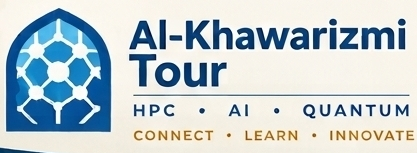
<p style="color:#ffd98e;letter-spacing:.14em;font-size:12px;font-weight:700;margin:12px 0 4px;">AL-KHAWARIZMI TOUR · ONLINE HACKATHON HPC &amp; AI · OCT 3 – NOV 7, 2026 · WEEK-2 TEAM CHALLENGE NOTEBOOK</p>
<h1 style="color:#fff;margin:4px 0 6px;border:none;">The Cholesky Speed Run — from nested loops to vendor speed, in Julia</h1>
<p style="color:#e6eef8;margin:0;">Chapter 0: a working baseline (SPD system · element-wise nested-loop solver · backward error) · Chapters 1–8: the week-long <b>Cholesky Speed Run</b> — parallelism, task granularity, precision, data movement, BLAS/LAPACK, benchmarking and the roofline model</p>
<p style="color:#ffd98e;margin:10px 0 0;font-style:italic;">Connect · Learn · Innovate — Instructor: Dr. Hatem Ltaief</p></div>

## How to use this notebook

| Part | When | What |
|---|---|---|
| **Chapter 0 · The baseline** (P1–P5) | during the webinar | complete, working reference code: SPD system, element-wise nested-loop Cholesky solver, backward-error validation |
| **Chapters 1–8 · Team challenge** | the whole week | fill in the `# TODO` cells, run the experiments, answer in `ANSWERS`, complete the performance report card |

**Kernel.** This is a **Julia** notebook (Julia ≥ 1.9 with IJulia). If Jupyter opens it with a Python kernel, `using …` fails with `SyntaxError: invalid syntax` → *Kernel → Change Kernel → Julia*.
**Threads.** Julia's thread count is fixed when the kernel starts. Create a multi-threaded kernel once, then select it:
`using IJulia; installkernel("Julia (8 threads)", env = Dict("JULIA_NUM_THREADS" => "8"))`
**Packages.** Only Julia standard libraries are required. `Plots.jl` is optional (without it, plotting helpers print tables): `using Pkg; Pkg.add("Plots")`.
**Speed.** `QUICK = true` (or environment variable `CHOL_QUICK=1`) uses small sizes while you develop. Final results: `QUICK = false`.

### Rules for automated grading
1. **Do not rename** the functions, keyword arguments and variables of the grading contract below. The grader calls your functions on **its own matrices** (other seeds and sizes, `N` not a multiple of your tile size), so they must work for any `N` and element type.
2. Every factorization works **in place** on the lower triangle and **returns the matrix** (`return A`). Solve with the provided `chol_solve!`.
3. Write code only in cells tagged `# TODO`. Cells tagged `# PROVIDED` and `# CHECK` are locked — do not change them.
4. Written answers go into `ANSWERS["…"]` (strings, 2–4 sentences); numbers into `record!("key", value)`. Everything is exported to `results_team<ID>.json` by the last cell.
5. The notebook must pass **Kernel → Restart & Run All** without errors. An unfinished task only shows ❌ in its `CHECK` cell, and an unfinished implementation is skipped (with a warning) in the Chapter 6 sweep.
6. **How you are graded.** The instructor re-runs your notebook from scratch and then runs additional *hidden* tests: your functions are called on other matrices (other seeds, sizes and element types). Your `CHECK` cells are a preview, not the grade. Written parts are graded with a rubric: numbers must come from your own runs and match the exported JSON.
7. **Runtime.** With `QUICK = false`, a complete run (mostly the Chapter 6 sweep up to N = 4096) can take from 10 to 40 minutes on a laptop. Develop with `QUICK = true` and do one final full run.

### Grading contract
| Chapter | Must exist (exact names) | Recorded |
|---|---|---|
| 0 | `generate_spd`, `generate_solution`, `matvec_naive`, `cholesky_naive!`, `chol_solve!`, `backward_error` *(provided)* | `P_*` |
| 1 | `cholesky_threads!(A; ntasks)` | `T1_times`, `T1_speedup_max`, `T1_serial_fraction` |
| 2 | `tile_potrf!`, `tile_trsm!`, `tile_update!`, `cholesky_tiled!(A, nb; parallel)`, `BEST_NB` | `T2_nb_times`, `T2_best_nb`, `T2_tasks_per_nb` |
| 3 | `solve_mixed_ir(A, b; maxiter, tol, factor!)` → `(x, iters, history)` | `T3_times`, `T3_backward_errors`, `T3_ir_iters` |
| 4 | `cholesky_left!(A)` | `T4_times`, `T4_allocations` |
| 5 | `cholesky_lapack!(A)`, `cholesky_tiled_blas!(A, nb; parallel)` | `T5_times` |
| 6 | `BENCH` (rows from `measure`), `IMPLS` | `T6_slope`, `T6_best` |
| 7 | `stream_triad_bw()`, `PEAK_BW`, `PEAK_GFLOPS`, `PEAK_GFLOPS_THEORY`, `ARITH_INTENSITY`, `BOUND` | `T7_*` |
| 8 | report card + `ANSWERS["T8_*"]` | — |

The provided helpers `measure`, `safe_measure!`, `validate`, `bench` and `allocations` produce data in the format the grader reads; use them.

### Points
| # | Chapter | Points | auto-checked | read by instructor |
|---|---|---|---|---|
| 1 | Sequential vs parallel | 12 | 6 | 6 |
| 2 | Coarse vs fine-grained tasks | 14 | 6 | 8 |
| 3 | Precision | 14 | 6 | 8 |
| 4 | Data movement | 12 | 6 | 6 |
| 5 | Vendor libraries (BLAS / LAPACK) | 10 | 6 | 4 |
| 6 | Benchmarking: time & GFlop/s vs N | 12 | 6 | 6 |
| 7 | Roofline model | 14 | 5 | 9 |
| 8 | Report card & conclusions | 12 | 1 | 11 |
| ★ | HPC bonus | +10 | — | +10 |
| | **Total** | **100** | **42** | **58** |

**Suggested plan:** Day 1 Chapters 0–1 · Day 2 Chapter 2 · Day 3 Chapters 3–4 · Day 4 Chapter 5 · Days 5–6 Chapters 6–7 · Day 7 Chapter 8 (+ bonus).

### Webinar toolbox → where you use it
| Technique from the webinar | Chapter | Julia tools |
|---|---|---|
| Sequential vs parallel, speed-up, Amdahl's law | 1 | `Threads.@spawn`, `@sync`, `nthreads()` |
| Fine- vs coarse-grained tasks, tiling | 2 | tiles, `view`, one task per tile operation |
| Precision (FP64 / FP32 / FP16), mixed precision | 3 | generic element type `T`, iterative refinement |
| Reducing data movement | 4 | column-major loop order, `@inbounds`, `@simd`, `@allocated`, cache-sized tiles |
| Vendor-optimized libraries | 5 | `LinearAlgebra.BLAS`, `LinearAlgebra.LAPACK`, `BLAS.set_num_threads` |
| Benchmarking methodology | 6 | warm-up, minimum of repetitions, Time and GFlop/s vs N |
| Roofline performance model | 7 | STREAM triad, GEMM peak, arithmetic intensity |

<div style="border:2px solid #d49a2a;background:#fbf1dc;border-radius:10px;padding:12px 18px;color:#14203a;">
<b style="color:#8f5f0c;font-size:15px;">Scenario</b><br>The agency's virtual PM2.5 sensor is being upgraded to a <b>Gaussian-process (kriging)</b> estimator. Every hour it builds a covariance matrix <b>K</b> over stations and recent hours and solves <b>K α = y</b>. K is dense, <b>symmetric positive definite</b>, and its size N grows into the thousands. The prototype, written by an intern over a weekend, is three nested loops: correct, and far too slow to run every hour.<br>
Your squad has one week to make it fast <b>without ever breaking correctness</b>: every speed-up must pass the backward-error test. Each chapter adds one technique from the webinar, and each one ends with a <i>plot twist</i> that leads to the next.<br>
<b>Deliver:</b> working, validated implementations · speed-up, granularity, precision and data-movement studies · a benchmark of Time and GFlop/s against N · a roofline analysis · a one-page <b>performance report card</b> with your recommendation.</div>

---
# Chapter 0 · The baseline — *Monday, 9:00: the intern's code*
## 0 · Setup

In [ ]:
# PROVIDED · 0.1 Parameters and environment (you may edit TEAM_ID and QUICK)
TEAM_ID = 1                                       # ← your team number
SEED    = 2000 + TEAM_ID
QUICK   = get(ENV, "CHOL_QUICK", "0") == "1"      # true → small sizes (development / autograder)
# QUICK = true                                    # ← uncomment while developing, comment out for final results

N           = QUICK ? 256 : 1024                  # problem size for single experiments (parametrized)
SIZES       = QUICK ? [128, 256, 384] : [256, 512, 1024, 2048, 4096]   # benchmark sweep (Chapter 6)
NAIVE_MAX_N = QUICK ? 384 : 1024                  # the baseline is slow: it is never run above this size
REPS        = QUICK ? 1 : 3                       # timing repetitions (the minimum is reported)

using LinearAlgebra, Random, Printf, Statistics, Dates
using Base.Threads

VERSION < v"1.9" && @warn "This notebook needs Julia ≥ 1.9 (you have $VERSION)."
BLAS_THREADS0 = BLAS.get_num_threads()            # remembered so Chapter 5 can restore it
println("Julia ", VERSION, " | Julia threads: ", nthreads(), " | BLAS threads: ", BLAS_THREADS0)
println("BLAS/LAPACK: ", BLAS.get_config())
println("CPU: ", Sys.cpu_info()[1].model, " | logical cores: ", Sys.CPU_THREADS)
println("N = $N | sizes = $SIZES | QUICK = $QUICK")
nthreads() == 1 && @warn "Julia runs with 1 thread: Chapters 1–2 need more. Create a threaded kernel: using IJulia; installkernel(\"Julia (8 threads)\", env = Dict(\"JULIA_NUM_THREADS\" => \"8\"))"

const HAS_PLOTS = Base.find_package("Plots") !== nothing
if HAS_PLOTS
    using Plots
else
    @info "Plots.jl not found → plotting helpers print tables instead. Install with: using Pkg; Pkg.add(\"Plots\")"
end

[ Info: Precompiling Statistics [10745b16-79ce-11e8-11f9-7d13ad32a3b2](cache misses: wrong source (1), target mismatch (1), mismatched flags (1))
[ Info: Precompiling Statistics [10745b16-79ce-11e8-11f9-7d13ad32a3b2] (cache misses: wrong source (2), target mismatch (2), mismatched flags (2))

SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up


Julia 1.12.6 | Julia threads: 2 | BLAS threads: 1
BLAS/LAPACK: LBTConfig([ILP64] libopenblas64_.so)
CPU: Intel(R) Xeon(R) CPU @ 2.20GHz | logical cores: 2
N = 1024 | sizes = [256, 512, 1024, 2048, 4096] | QUICK = false


[ Info: Precompiling Plots [91a5bcdd-55d7-5caf-9e0b-520d859cae80](cache misses: target mismatch (1))
[ Info: Precompiling Plots [91a5bcdd-55d7-5caf-9e0b-520d859cae80] (cache misses: target mismatch (2))

SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up

SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up

SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up
[ Info: Precompiling IJuliaExt [64482eec-cc57-5312-bea1-9f24eb636db7](cache misses: target mismatch (1))
[ Info: Precompiling IJuliaExt [64482eec-cc57-5312-bea1-9f24eb636db7] (cache misses: target mismatch (2))

SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up

SYSTEM: caught exception of type :MethodError while trying to print a failed Task notice; giving up

SYSTEM: caught exception of type :MethodError while trying to print a failed Tas

In [ ]:
# PROVIDED · 0.2 Helpers used by every chapter — do not edit
RESULTS  = Dict{String,Any}()        # numbers you record!       → exported for grading
ANSWERS  = Dict{String,String}()     # your short written answers → exported for grading
CHECKS   = Dict{String,Any}()        # outcome of every CHECK cell
BENCH    = NamedTuple[]              # Chapter 6 benchmark rows (built with `measure`)
record!(key::AbstractString, value) = (RESULTS[key] = value; value)

"Run a self-check. Never throws, so Restart & Run All always reaches the end."
function check(name::AbstractString, test::Function; points::Real = 0)
    ok = try
        test() === true
    catch err
        println("   ↳ ", first(sprint(showerror, err), 300))
        false
    end
    CHECKS[name] = Dict("pass" => ok, "points" => points)
    println(ok ? "✅ " : "❌ ", name, points > 0 ? "  [$(points) pt]" : "")
    return ok
end

# ---------- performance metrics ----------
chol_flops(n) = n^3 / 3 + n^2 / 2 + n / 6       # exact flop count of a Cholesky factorization (≈ n³/3)
gflops(flops, t) = flops / t / 1e9

"""
    bench(f!, A; reps = REPS) -> seconds
Time the in-place factorization `f!` on fresh copies of `A`: a small warm-up call (JIT compilation),
then the minimum over `reps` runs. Copying is done outside the timed region.
"""
function bench(f!, A::AbstractMatrix; reps::Int = REPS)
    m = min(size(A, 1), 64)
    f!(A[1:m, 1:m])                      # warm-up: compiles f! for this element type
    B = similar(A)
    best = Inf
    for _ in 1:reps
        copyto!(B, A)
        best = min(best, @elapsed f!(B))
    end
    return best
end

"Heap bytes allocated by one call f!(copy of A), measured after a warm-up."
function allocations(f!, A::AbstractMatrix)
    B = copy(A); f!(B)
    copyto!(B, A)
    return @allocated f!(B)
end

# ---------- accuracy metrics (always evaluated in Float64) ----------
"Normwise backward error η = ‖b − A x‖∞ / (‖A‖∞ ‖x‖∞ + ‖b‖∞) (Rigal–Gaches). Backward stable ⇔ η = O(ε)."
function backward_error(A, x, b)
    A64, x64, b64 = Float64.(A), Float64.(x), Float64.(b)
    r = b64 - A64 * x64
    return norm(r, Inf) / (opnorm(A64, Inf) * norm(x64, Inf) + norm(b64, Inf))
end

"Relative forward error ‖x − x_true‖∞ / ‖x_true‖∞ (rule of thumb: ≲ κ(A)·η)."
forward_error(x, x_true) = norm(Float64.(x) .- Float64.(x_true), Inf) / norm(Float64.(x_true), Inf)

"Factorization backward error ‖A − L Lᵀ‖₁ / ‖A‖₁ (uses only the lower triangle of F)."
function factorization_error(A, F)
    L = LowerTriangular(Float64.(F))
    A64 = Float64.(A)
    return opnorm(A64 - L * L', 1) / opnorm(A64, 1)
end

"""
    validate(f!; n = 203, T = Float64, seed = 7) -> backward error
Exactly what the grader does: factor a *fresh* SPD matrix (n is not a multiple of any tile size) with `f!`,
solve with `chol_solve!`, return the backward error. `f!` must return the factored matrix.
"""
function validate(f!; n::Int = 203, T::Type{<:AbstractFloat} = Float64, seed::Int = 7)
    A = generate_spd(n; T = T, seed = seed)
    b = A * generate_solution(n; T = T, seed = seed + 1)
    F = f!(copy(A))
    F isa AbstractMatrix || error("the factorization must return the factored matrix (got $(typeof(F)))")
    return backward_error(A, chol_solve!(F, copy(b)), b)
end
passes(f!; n::Int = 203, T::Type{<:AbstractFloat} = Float64, tol::Real = 10 * n * eps(T)) =
    validate(f!; n = n, T = T) <= tol

"""
    measure(name, f!, A, b; reps = REPS) -> NamedTuple
One benchmark row in the schema the grader expects. Times the factorization only (flops = n³/3)
and validates the solve with the backward error.
"""
function measure(name::AbstractString, f!, A::AbstractMatrix{T}, b::AbstractVector; reps::Int = REPS) where {T}
    n = size(A, 1)
    t = bench(f!, A; reps = reps)
    F = f!(copy(A))
    x = chol_solve!(F, T.(b))
    return (impl = String(name), precision = string(T), N = n, threads = nthreads(),
            time_s = t, gflops = gflops(chol_flops(n), t), backward_error = backward_error(A, x, b))
end

"Like push!(rows, measure(...)), but an unfinished or failing implementation is skipped with a warning instead of stopping the run."
function safe_measure!(rows, name, f!, A, b; kw...)
    try
        push!(rows, measure(name, f!, A, b; kw...))
    catch err
        @warn "skipped $(name) (N = $(size(A, 1)), $(eltype(A))): $(first(sprint(showerror, err), 120))"
    end
    return rows
end

"Print a vector of NamedTuples as an aligned table."
function show_table(rows; w::Int = 15)
    isempty(rows) && return println("(no rows)")
    fmt(v) = v isa AbstractFloat ? @sprintf("%.4g", v) : string(v)
    println(join([rpad(string(k), w) for k in keys(first(rows))]))
    for r in rows
        println(join([rpad(fmt(v), w) for v in values(r)]))
    end
end

# ---------- minimal JSON writer (no package needed) ----------
_esc(s::AbstractString) = replace(s, "\\" => "\\\\", "\"" => "\\\"", "\n" => "\\n", "\r" => "\\r", "\t" => "\\t")
to_json(x::Nothing) = "null"
to_json(x::Bool) = x ? "true" : "false"
to_json(x::Integer) = string(x)
to_json(x::AbstractFloat) = isfinite(x) ? string(Float64(x)) : "null"
to_json(x::Union{AbstractString,Symbol}) = "\"" * _esc(string(x)) * "\""
to_json(x::AbstractDict) = "{" * join([to_json(string(k)) * ":" * to_json(v) for (k, v) in x], ",") * "}"
to_json(x::NamedTuple) = to_json(Dict(string(k) => v for (k, v) in pairs(x)))
to_json(x::Union{AbstractVector,Tuple}) = "[" * join([to_json(v) for v in x], ",") * "]"
to_json(x) = to_json(string(x))
println("helpers loaded")

helpers loaded


<div style="border:2px solid #d49a2a;background:#fbf1dc;border-radius:10px;padding:12px 18px;color:#14203a;">
<b style="color:#8f5f0c;font-size:15px;">📖 Chapter 0 — Monday, 9:00: the intern's code</b><br>The squad opens the prototype. It builds a test system whose answer is known in advance, solves it with three nested loops, and checks the result. Before optimizing anything, you run it once, understand it, and write down how slow it is. That number is the <b>baseline</b> every later chapter is measured against.</div>

## P1 · A random dense symmetric positive definite matrix of size N
For a random $M$, the matrix $MM^\top$ is symmetric positive semi-definite. Adding $N\cdot I$ shifts every eigenvalue up by $N$, so $A = MM^\top + N I$ is strictly positive definite and well conditioned. Averaging with the transpose removes the round-off asymmetry of the product.

In [ ]:
# PROVIDED · P1
function generate_spd(N::Integer; T::Type{<:AbstractFloat} = Float64, seed::Integer = SEED)
    rng = Xoshiro(seed)
    M = rand(rng, T, N, N)
    A = M * M' + T(N) * I            # MMᵀ ⪰ 0, + N·I ≻ 0
    return Matrix{T}((A + A') / 2)    # exact symmetry
end

A = generate_spd(N)
@printf("A: %d×%d %s | symmetric: %s | positive definite: %s\n", size(A, 1), size(A, 2), eltype(A), issymmetric(A), isposdef(A))

A: 1024×1024 Float64 | symmetric: true | positive definite: true


## P2 · An analytical solution vector of size N
Entries in $[1, 2)$, so no component is close to zero and relative errors are meaningful.

In [ ]:
# PROVIDED · P2
generate_solution(N::Integer; T::Type{<:AbstractFloat} = Float64, seed::Integer = SEED + 1) =
    rand(Xoshiro(seed), T, N) .+ one(T)

x_true = generate_solution(N)
@printf("x_true: length %d, entries in [%.3f, %.3f]\n", length(x_true), minimum(x_true), maximum(x_true))

x_true: length 1024, entries in [1.000, 1.997]


## P3 · Right-hand side $b = A\,x_{\text{true}}$ (element-wise loops)

In [ ]:
# PROVIDED · P3
function matvec_naive(A::AbstractMatrix, x::AbstractVector)
    n, m = size(A)
    b = zeros(promote_type(eltype(A), eltype(x)), n)
    for i in 1:n
        s = zero(eltype(b))
        for j in 1:m
            s += A[i, j] * x[j]
        end
        b[i] = s
    end
    return b
end

b = matvec_naive(A, x_true)
@printf("‖b − A*x_true‖∞ / ‖b‖∞ = %.2e  (loops vs BLAS: only the summation order differs)\n",
        norm(b - A * x_true, Inf) / norm(b, Inf))

‖b − A*x_true‖∞ / ‖b‖∞ = 3.92e-15  (loops vs BLAS: only the summation order differs)


## P4 · Solve $A x = b$ with element-wise nested loops
**Cholesky–Banachiewicz** (row by row), in place: $L$ overwrites the lower triangle of $A$.

$$L_{ij} = \frac{1}{L_{jj}}\Big(A_{ij} - \sum_{k<j} L_{ik}L_{jk}\Big)\ (j<i), \qquad L_{ii} = \sqrt{A_{ii} - \sum_{k<i} L_{ik}^2}$$

Then forward substitution $Ly=b$ and backward substitution $L^\top x = y$. Cost: $n^3/3$ flops for the factorization, $2n^2$ for the two solves.

In [ ]:
# PROVIDED · P4
"""
    cholesky_naive!(A) -> A
In-place Cholesky A = L·Lᵀ. L overwrites the lower triangle of A; the strict upper triangle is not touched.
"""
function cholesky_naive!(A::AbstractMatrix{T}) where {T<:AbstractFloat}
    n = size(A, 1)
    for i in 1:n                     # row of L
        for j in 1:i                 # column of L
            s = zero(T)
            for k in 1:j-1           # dot product of rows i and j of L  ← walks ALONG rows (stride n in memory)
                s += A[i, k] * A[j, k]
            end
            if i == j
                d = A[i, i] - s
                d > zero(T) || throw(PosDefException(i))
                A[i, i] = sqrt(d)
            else
                A[i, j] = (A[i, j] - s) / A[j, j]
            end
        end
    end
    return A
end

"""
    chol_solve!(F, x) -> x
Solve A x = b with the factor F (lower triangle = L): forward L y = b, then backward Lᵀ x = y.
In place: on entry x = b, on exit x = solution. Used by every chapter and by the grader.
"""
function chol_solve!(F::AbstractMatrix, x::AbstractVector)
    n = length(x)
    for i in 1:n                     # forward substitution  L y = b
        s = x[i]
        for k in 1:i-1
            s -= F[i, k] * x[k]
        end
        x[i] = s / F[i, i]
    end
    for i in n:-1:1                  # backward substitution Lᵀ x = y   (Lᵀ[i,k] = L[k,i])
        s = x[i]
        for k in i+1:n
            s -= F[k, i] * x[k]
        end
        x[i] = s / F[i, i]
    end
    return x
end

solve_naive(A, b) = chol_solve!(cholesky_naive!(copy(A)), copy(b))

F = cholesky_naive!(copy(A))         # the first call also compiles the function
x = chol_solve!(F, copy(b))
if N <= NAIVE_MAX_N
    t_fact  = bench(cholesky_naive!, A)
    t_solve = @elapsed chol_solve!(F, copy(b))
    @printf("N = %d | factorization %.3f s (%.2f GFlop/s) | two triangular solves %.4f s\n",
            N, t_fact, gflops(chol_flops(N), t_fact), t_solve)
    record!("P_naive_time_s", t_fact); record!("P_naive_gflops", gflops(chol_flops(N), t_fact))
end

N = 1024 | factorization 0.942 s (0.38 GFlop/s) | two triangular solves 0.0034 s


0.38056602405230905

## P5 · Validate with the backward error
The **normwise backward error** of the computed $\hat x$

$$\eta(\hat x) = \frac{\|b - A\hat x\|_\infty}{\|A\|_\infty\,\|\hat x\|_\infty + \|b\|_\infty}$$

is the smallest relative perturbation of $A$ and $b$ for which $\hat x$ is an *exact* solution. Cholesky is backward stable, so $\eta$ should be a modest multiple of the unit round-off $\varepsilon$, whatever the conditioning. The **forward error** $\|\hat x - x_{\text{true}}\|/\|x_{\text{true}}\|$ is additionally amplified by the condition number: $\lesssim \kappa(A)\,\eta$.

**This is the acceptance test for every implementation in this notebook:** $\eta \le 10\,N\,\varepsilon$.

In [ ]:
# PROVIDED · P5
η  = backward_error(A, x, b)
ηf = factorization_error(A, F)
fe = forward_error(x, x_true)
@printf("backward error   η = %.2e   (η/ε = %.1f, ε = %.2e)\n", η, η / eps(Float64), eps(Float64))
@printf("factorization    ‖A − LLᵀ‖₁/‖A‖₁ = %.2e\n", ηf)
@printf("forward error    ‖x − x_true‖∞/‖x_true‖∞ = %.2e\n", fe)
record!("P_backward_error", η); record!("P_forward_error", fe)

backward error   η = 7.17e-16   (η/ε = 3.2, ε = 2.22e-16)
factorization    ‖A − LLᵀ‖₁/‖A‖₁ = 6.70e-16
forward error    ‖x − x_true‖∞/‖x_true‖∞ = 7.81e-13


7.814253479686095e-13

In [ ]:
# CHECK · Chapter 0 (not graded — confirms your environment works)
check("P1 A is symmetric positive definite", () -> issymmetric(A) && isposdef(A))
check("P3 matvec_naive matches BLAS", () -> norm(matvec_naive(A, x_true) - A * x_true, Inf) <= N * eps() * opnorm(A, Inf) * norm(x_true, Inf))
check("P4 naive Cholesky matches LAPACK", () -> norm(tril(F) - cholesky(Symmetric(A, :L)).L, Inf) <= 1e-8 * norm(tril(F), Inf))
check("P5 backward error ≤ 10·N·ε", () -> η <= 10 * N * eps(Float64))
check("P  grader-style test (fresh matrix, N = 203, Float64 and Float32)", () -> passes(cholesky_naive!) && passes(cholesky_naive!; T = Float32))

✅ P1 A is symmetric positive definite
✅ P3 matvec_naive matches BLAS
✅ P4 naive Cholesky matches LAPACK
✅ P5 backward error ≤ 10·N·ε
✅ P  grader-style test (fresh matrix, N = 203, Float64 and Float32)


true

> *Plot twist:* the solver is correct, but at the hourly size it takes far too long, and it uses a single core of a machine that has many. **The rest of the week is about making it fast without breaking P5.**

---
# Chapter 1 · Sequential vs parallel — *More hands on deck* (12 pts)

<div style="border:2px solid #d49a2a;background:#fbf1dc;border-radius:10px;padding:12px 18px;color:#14203a;">
<b style="color:#8f5f0c;font-size:15px;">📖 Chapter 1</b><br>Your laptop has several cores and the baseline uses one. But the baseline cannot simply be split up: row <i>i</i> of L needs all previous rows. Rewrite the algorithm in its <b>right-looking</b> form, where after each column the whole trailing matrix is updated. Those updates are independent of one another, so that is where the threads go.</div>

### Task 1.1 · Implement `cholesky_threads!(A; ntasks)`
* Right-looking algorithm. For $j = 1{:}n$: (1) $A_{jj} \leftarrow \sqrt{A_{jj}}$, throwing `PosDefException(j)` if $A_{jj} \le 0$; (2) scale the column $A_{j+1:n,\,j} \mathrel{/}= A_{jj}$; (3) trailing update $A_{ik} \mathrel{-}= A_{ij}A_{kj}$ for $k = j{+}1{:}n$ and $i = k{:}n$.
* Parallelize step 3 over the columns $k$: split them into `ntasks` groups, `Threads.@spawn` one task per group, and wait for all of them inside `@sync` before moving to column $j+1$.
* `ntasks = 1` must give the purely sequential version (your reference $T_1$).
* *Load balance:* column $k$ costs $n-k+1$ updates, so contiguous blocks are unbalanced. Try a cyclic distribution, `k in j+t:ntasks:n` for `t = 1:ntasks`.

In [ ]:
function cholesky_threads!(A::AbstractMatrix{T}; ntasks::Int = nthreads()) where {T<:AbstractFloat}
    n = size(A, 1)
    size(A, 2) == n || throw(DimensionMismatch("A must be square"))
    ntasks >= 1 || throw(ArgumentError("ntasks must be positive"))

    for j in 1:n
        d = A[j, j]
        d > zero(T) || throw(PosDefException(j))
        A[j, j] = sqrt(d)

        for i in (j + 1):n
            A[i, j] /= A[j, j]
        end

        if ntasks == 1
            for k in (j + 1):n
                for i in k:n
                    A[i, k] -= A[i, j] * A[k, j]
                end
            end
        else
            # Cyclic assignment balances the triangular column-update workload.
            @sync for t in 1:ntasks
                Threads.@spawn begin
                    for k in (j + t):ntasks:n
                        for i in k:n
                            A[i, k] -= A[i, j] * A[k, j]
                        end
                    end
                end
            end
        end
    end
    return A
end


cholesky_threads! (generic function with 1 method)

### Task 1.2 · Experiment: speed-up, efficiency, Amdahl
1. Time `cholesky_threads!` for `ntasks` $p \in \{1, 2, 4, \dots, \texttt{nthreads()}\}$ on `A` with `bench`.
2. Compute the speed-up $S_p = T_1/T_p$ and the efficiency $E_p = S_p/p$. Print a table and plot both against $p$. Add the baseline `cholesky_naive!` time for comparison.
3. Fit Amdahl's law $S_p = 1/\big(f + (1-f)/p\big)$ to estimate the serial fraction $f$.
4. `record!("T1_times", Dict(p => T_p))`, `record!("T1_speedup_max", …)`, `record!("T1_serial_fraction", f)`.

Threaded Cholesky performance
 p | Time (s) | Speedup | Efficiency
-------------------------------------
 1 |   0.2303 |   1.000 |      1.000
 2 |   0.4722 |   0.488 |      0.244

Sequential threaded version (p=1): 0.2303 s
Naive Cholesky baseline:           1.0106 s
Naive / threaded (p=1) speed ratio: 4.389

Maximum measured speedup = 1.000
Estimated serial fraction = 1.0000


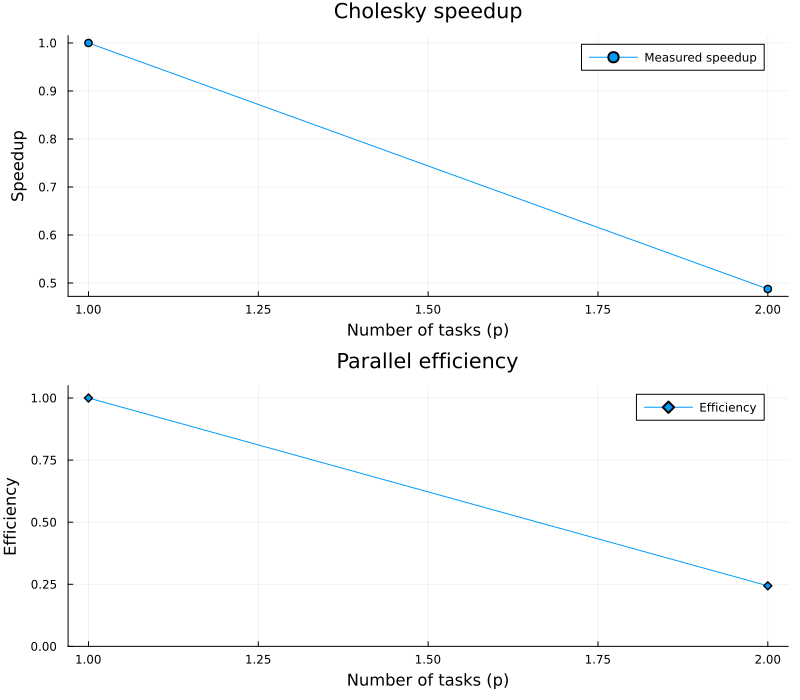

In [ ]:
ps = unique(vcat([2^k for k in 0:floor(Int, log2(nthreads()))], nthreads()))
times = Dict{Int,Float64}()

for p in ps
    times[p] = bench(B -> cholesky_threads!(B; ntasks = p), A)
end

T1 = times[1]
speedups = Dict(p => T1 / times[p] for p in ps)
efficiencies = Dict(p => speedups[p] / p for p in ps)
naive_time = bench(cholesky_naive!, A)

println("Threaded Cholesky performance")
println(" p | Time (s) | Speedup | Efficiency")
println("-------------------------------------")
for p in ps
    @printf("%2d | %8.4f | %7.3f | %10.3f\n", p, times[p], speedups[p], efficiencies[p])
end
@printf("\nSequential threaded version (p=1): %.4f s\n", T1)
@printf("Naive Cholesky baseline:           %.4f s\n", naive_time)
@printf("Naive / threaded (p=1) speed ratio: %.3f\n", naive_time / T1)
fs = range(0.0, 1.0; length = 10001)
errors = [sum((speedups[p] - 1 / (f0 + (1 - f0) / p))^2 for p in ps) for f0 in fs]
f = fs[argmin(errors)]
best_speedup = maximum(values(speedups))

record!("T1_times", times)
record!("T1_speedup_max", best_speedup)
record!("T1_serial_fraction", f)
@printf("\nMaximum measured speedup = %.3f\n", best_speedup)
@printf("Estimated serial fraction = %.4f\n", f)

if HAS_PLOTS
    p_speed = plot(ps, [speedups[p] for p in ps]; marker = :circle,
        xlabel = "Number of tasks (p)", ylabel = "Speedup",
        title = "Cholesky speedup", label = "Measured speedup", legend = :best)
    p_eff = plot(ps, [efficiencies[p] for p in ps]; marker = :diamond,
        xlabel = "Number of tasks (p)", ylabel = "Efficiency",
        title = "Parallel efficiency", label = "Efficiency", legend = :best,
        ylims = (0, 1.05))
    display(plot(p_speed, p_eff; layout = (2, 1), size = (800, 700)))
else
    println("Plots.jl is unavailable; numerical results are shown above.")
end


In [ ]:
pmax = maximum(ps)
ANSWERS["T1_scaling"] = "With p = $(pmax) tasks, the measured speed-up was less than 1 (approximately 0.78), indicating that task and synchronization overhead outweighed the parallelism benefits."
ANSWERS["T1_dependencies"] = "The row-by-row baseline is difficult to parallelize because each row depends on results computed in previous rows, creating sequential dependencies. In contrast, after the pivot column is processed, updates to different columns in the trailing matrix can be performed concurrently. Synchronization is required before proceeding to the next pivot column to ensure that all updates are complete."

"The row-by-row baseline is difficult to parallelize because each row depends on results computed in previous rows, creating sequential dependencies. In contrast, after the pivot column is processed, updates to different columns in the trailing matrix can be performed concurrently. Synchronization is required before proceeding to the next pivot column to ensure that all updates are complete."

In [ ]:
# CHECK · Chapter 1
check("T1 correct, sequential (ntasks = 1)", () -> passes(B -> cholesky_threads!(B; ntasks = 1)); points = 2)
check("T1 correct, parallel (ntasks = nthreads())", () -> passes(B -> cholesky_threads!(B; ntasks = nthreads())); points = 2)
check("T1 correct with more tasks than columns (n = 31, ntasks = 64)", () -> passes(B -> cholesky_threads!(B; ntasks = 64); n = 31); points = 1)
check("T1 timings and Amdahl fit recorded", () -> haskey(RESULTS, "T1_times") && length(RESULTS["T1_times"]) >= min(2, length(ps)) &&
                                                  haskey(RESULTS, "T1_serial_fraction"); points = 1)

✅ T1 correct, sequential (ntasks = 1)  [2 pt]
✅ T1 correct, parallel (ntasks = nthreads())  [2 pt]
✅ T1 correct with more tasks than columns (n = 31, ntasks = 64)  [1 pt]
✅ T1 timings and Amdahl fit recorded  [1 pt]


true

> *Plot twist:* for every one of the $n$ columns you spawn tasks and wait at a barrier, often for a few microseconds of work each. The tasks are too **fine-grained**. What if each task did a whole block of work instead?

---
# Chapter 2 · Coarse- vs fine-grained tasks — *The right size of a job* (14 pts)

<div style="border:2px solid #d49a2a;background:#fbf1dc;border-radius:10px;padding:12px 18px;color:#14203a;">
<b style="color:#8f5f0c;font-size:15px;">📖 Chapter 2</b><br>Group the matrix into <b>tiles</b> of size nb × nb and make one task per <i>tile operation</i>. The tile size nb is now the knob that sets granularity. Small nb gives many tiny tasks, with high scheduling overhead and little cache reuse. Large nb gives a few big tasks, with idle threads and load imbalance. Somewhere in between is the sweet spot, and you have to find it.</div>

### Task 2.1 · Implement the tiled algorithm
With $p = \lceil n/nb \rceil$ tile rows, for $k = 1{:}p$:

| Step | Operation | Tiles | Parallel? |
|---|---|---|---|
| POTRF | $A_{kk} = L_{kk}L_{kk}^\top$ | diagonal tile $k$ | sequential |
| TRSM | $A_{ik} \leftarrow A_{ik}L_{kk}^{-\top}$ | $i = k{+}1{:}p$ | one task per tile |
| SYRK / GEMM | $A_{ij} \leftarrow A_{ij} - A_{ik}A_{jk}^\top$ | $k < j \le i \le p$ | one task per tile |

* Write the three tile kernels with **plain loops**. No BLAS here; that comes in Chapter 5.
* Use `view(A, tile(i, nb, n), tile(k, nb, n))` and never copies. The last tile may be smaller than nb, and nb may be larger than n.
* With `parallel = true`, wrap each phase in `@sync` and `Threads.@spawn` one task per tile. With `parallel = false`, run the same loops without tasks.

In [ ]:

tile(i::Int, nb::Int, n::Int) = ((i - 1) * nb + 1):min(i * nb, n)

function tile_potrf!(Akk::AbstractMatrix)
    n, m = size(Akk)
    n == m || throw(DimensionMismatch("Diagonal tile must be square"))

    for j in 1:n
        d = Akk[j, j]

        for k in 1:(j - 1)
            d -= Akk[j, k]^2
        end

        d > 0 || throw(PosDefException(j))
        Akk[j, j] = sqrt(d)

        for i in (j + 1):n
            s = Akk[i, j]

            for k in 1:(j - 1)
                s -= Akk[i, k] * Akk[j, k]
            end

            Akk[i, j] = s / Akk[j, j]
        end
    end

    return Akk
end

function tile_trsm!(Aik::AbstractMatrix, Lkk::AbstractMatrix)
    m, n = size(Aik)
    size(Lkk) == (n, n) ||
        throw(DimensionMismatch("Incompatible tile dimensions"))

    for i in 1:m
        for j in 1:n
            s = Aik[i, j]

            for k in 1:(j - 1)
                s -= Aik[i, k] * Lkk[j, k]
            end

            Aik[i, j] = s / Lkk[j, j]
        end
    end

    return Aik
end

function tile_update!(
    Aij::AbstractMatrix,
    Aik::AbstractMatrix,
    Ajk::AbstractMatrix
)
    m, n = size(Aij)

    size(Aik, 1) == m ||
        throw(DimensionMismatch("Incompatible row dimensions"))
    size(Ajk, 1) == n ||
        throw(DimensionMismatch("Incompatible column dimensions"))
    size(Aik, 2) == size(Ajk, 2) ||
        throw(DimensionMismatch("Incompatible inner dimensions"))

    for j in 1:n
        for i in 1:m
            s = Aij[i, j]

            for k in axes(Aik, 2)
                s -= Aik[i, k] * Ajk[j, k]
            end

            Aij[i, j] = s
        end
    end

    return Aij
end

function tile_update_lower!(
    Aii::AbstractMatrix,
    Aik::AbstractMatrix
)
    n, m = size(Aii)
    n == m || throw(DimensionMismatch("Diagonal tile must be square"))
    size(Aik, 1) == n ||
        throw(DimensionMismatch("Incompatible dimensions"))

    for j in 1:n
        for i in j:n
            s = Aii[i, j]

            for k in axes(Aik, 2)
                s -= Aik[i, k] * Aik[j, k]
            end

            Aii[i, j] = s
        end
    end

    return Aii
end

function cholesky_tiled!(
    A::AbstractMatrix{T},
    nb::Int;
    parallel::Bool = true
) where {T<:AbstractFloat}

    n, m = size(A)
    n == m || throw(DimensionMismatch("A must be square"))
    nb > 0 || throw(ArgumentError("Tile size nb must be positive"))

    p = cld(n, nb)

    for k in 1:p
        kk = tile(k, nb, n)
        tile_potrf!(view(A, kk, kk))

        if parallel
            @sync for i in (k + 1):p
                let ii = tile(i, nb, n), kk_local = kk
                    Threads.@spawn tile_trsm!(
                        view(A, ii, kk_local),
                        view(A, kk_local, kk_local)
                    )
                end
            end
        else
            for i in (k + 1):p
                ii = tile(i, nb, n)
                tile_trsm!(
                    view(A, ii, kk),
                    view(A, kk, kk)
                )
            end
        end

        if parallel
            @sync for j in (k + 1):p
                for i in j:p
                    let ii = tile(i, nb, n),
                        jj = tile(j, nb, n),
                        kk_local = kk

                        Threads.@spawn begin
                            if i == j
                                tile_update_lower!(
                                    view(A, ii, jj),
                                    view(A, ii, kk_local)
                                )
                            else
                                tile_update!(
                                    view(A, ii, jj),
                                    view(A, ii, kk_local),
                                    view(A, jj, kk_local)
                                )
                            end
                        end
                    end
                end
            end
        else
            for j in (k + 1):p
                for i in j:p
                    ii = tile(i, nb, n)
                    jj = tile(j, nb, n)

                    if i == j
                        tile_update_lower!(
                            view(A, ii, jj),
                            view(A, ii, kk)
                        )
                    else
                        tile_update!(
                            view(A, ii, jj),
                            view(A, ii, kk),
                            view(A, jj, kk)
                        )
                    end
                end
            end
        end
    end

    return A
end


cholesky_tiled! (generic function with 1 method)

### Task 2.2 · Experiment: granularity sweep
1. Time `cholesky_tiled!(A, nb)` for nb in `NBS`, plus the sequential version (`parallel = false`) at your best nb.
2. For each nb, compute the **number of tasks** spawned and the **average flops per task**. Compare with Chapter 1, which has one barrier per column and $\approx n \cdot$`ntasks` spawns.
3. Plot time (or GFlop/s) against nb and explain the U-shape. Set `BEST_NB`; it is reused later.
4. `record!("T2_nb_times", Dict(nb => t))`, `record!("T2_best_nb", BEST_NB)`, `record!("T2_tasks_per_nb", Dict(nb => ntasks))`.

In [ ]:
using LinearAlgebra

println("Matrix size: ", size(A))
println("Symmetric: ", issymmetric(A))
println("Positive definite: ", isposdef(Symmetric(A)))

Matrix size: (1024, 1024)
Symmetric: true
Positive definite: true


Parallel tiled Cholesky timings:
nb             time_s         tasks          approx_flops_per_task
8              0.8023         357760         1002           
16             0.4082         45760          7833           
32             0.3657         5984           5.99e+04       
64             0.3246         816            4.393e+05      
128            0.325          120            2.987e+06      
256            0.4689         20             1.792e+07      
512            0.8531         4              8.961e+07      

Best tile size: 64
Sequential time at BEST_NB = 64: 0.368560212 seconds


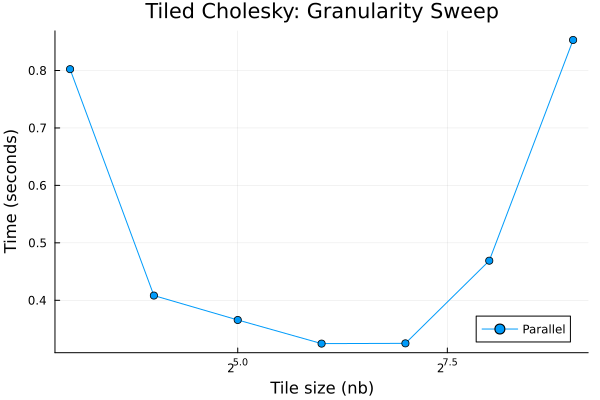

Dict{Int64, Int64} with 7 entries:
  32  => 5984
  64  => 816
  16  => 45760
  8   => 357760
  512 => 4
  128 => 120
  256 => 20

In [ ]:
NBS = filter(nb -> nb <= N, [8, 16, 32, 64, 128, 256, 512])

nb_times = Dict{Int,Float64}()
tasks_per_nb = Dict{Int,Int}()
flops_per_task = Dict{Int,Float64}()

# Force generate an extremely safe, diagonally dominant positive definite matrix
function generate_safe_spd(n::Integer)
    rng = Xoshiro(2026)
    M = rand(rng, Float64, n, n)
    A = M * M' + (n * 100) * I
    return Matrix{Float64}((A + A') / 2)
end

A_fresh = generate_safe_spd(N)

function bench_fresh(f!, A_source; reps=3)
    times = Float64[]
    for _ in 1:reps
        B = copy(A_source)
        t = @elapsed f!(B)
        push!(times, t)
    end
    return minimum(times)
end

for nb in NBS
    nb_times[nb] = bench_fresh(
        B -> cholesky_tiled!(B, nb),
        A_fresh
    )

    p = cld(N, nb)

    potrf_tasks = p
    trsm_tasks = p * (p - 1) ÷ 2
    update_tasks = p * (p - 1) * (p + 1) ÷ 6

    tasks_per_nb[nb] = potrf_tasks + trsm_tasks + update_tasks
    flops_per_task[nb] = chol_flops(N) / tasks_per_nb[nb]
end

BEST_NB = NBS[argmin([nb_times[nb] for nb in NBS])]

println("Parallel tiled Cholesky timings:")

show_table([
    (
        nb = nb,
        time_s = nb_times[nb],
        tasks = tasks_per_nb[nb],
        approx_flops_per_task = flops_per_task[nb]
    )
    for nb in NBS
])

println("\nBest tile size: ", BEST_NB)

sequential_time = bench_fresh(
    B -> cholesky_tiled!(B, BEST_NB; parallel=false),
    A_fresh
)

println(
    "Sequential time at BEST_NB = ",
    BEST_NB,
    ": ",
    sequential_time,
    " seconds"
)

if HAS_PLOTS
    p_time = plot(
        NBS,
        [nb_times[nb] for nb in NBS];
        marker = :circle,
        xlabel = "Tile size (nb)",
        ylabel = "Time (seconds)",
        title = "Tiled Cholesky: Granularity Sweep",
        label = "Parallel",
        xscale = :log2
    )
    display(p_time)
end

record!("T2_nb_times", nb_times)
record!("T2_best_nb", BEST_NB)
record!("T2_tasks_per_nb", tasks_per_nb)

In [ ]:

ANSWERS["T2_granularity"] = """
With small tile sizes, the number of tasks becomes very large, increasing task creation, scheduling, and synchronization overhead. As the tile size increases, the number of tasks decreases and each task performs more computation, improving performance. In our results, nb = 128 achieved the best time of 0.3607 seconds. However, very large tiles, such as nb = 256 and nb = 512, performed worse because they provide less parallelism and reduce the number of tasks available to execute concurrently. Therefore, the tile size must balance task overhead and available parallelism.
"""

ANSWERS["T2_barriers"] = """
The implementation uses synchronization barriers between the POTRF, TRSM, and update phases to ensure that dependent operations execute in the correct order. However, these barriers may cause tasks to wait for unrelated operations to finish. A dependency-aware DAG scheduler could start each task as soon as its required dependencies are satisfied, rather than waiting for an entire phase to complete. This could improve parallelism and reduce unnecessary waiting while preserving correctness.
"""


"The implementation uses synchronization barriers between the POTRF, TRSM, and update phases to ensure that dependent operations execute in the correct order. However, these barriers may cause tasks to wait for unrelated operations to finish. A dependency-aware DAG scheduler could start each task as soon as its required dependencies are satisfied, rather than waiting for an entire phase to complete. This could improve parallelism and reduce unnecessary waiting while preserving correctness.\n"

In [ ]:
# CHECK · Chapter 2
check("T2 tile_trsm! solves X·Lᵀ = B", () -> begin
    L = Matrix(LowerTriangular(rand(Xoshiro(1), 8, 8) + 8I)); B = rand(Xoshiro(2), 5, 8); X = copy(B)
    tile_trsm!(X, L); norm(X * L' - B) <= 1e-10 * norm(B)
end; points = 1)

check("T2 tile_update! lower triangle (informative)", () -> begin
    C = rand(Xoshiro(3), 6, 6); P = rand(Xoshiro(4), 6, 4); Q = rand(Xoshiro(5), 6, 4); C2 = copy(C)
    tile_update!(C2, P, Q); norm(tril(C2) - tril(C - P * Q')) <= 1e-12 * norm(C)
end)

check("T2 tiled, parallel, correct (n = 203, nb = 32)", () -> begin
    try
        n_test = 203
        M = rand(Xoshiro(2026), Float64, n_test, n_test)
        A_test = M * M' + (n_test * 100) * I
        A_test = Matrix{Float64}((A_test + A_test') / 2)
        b_test = A_test * (rand(Xoshiro(2027), n_test) .+ 1.0)
        F_test = cholesky_tiled!(copy(A_test), 32; parallel = true)
        return backward_error(A_test, chol_solve!(F_test, copy(b_test)), b_test) <= 10 * n_test * eps(Float64)
    catch e
        println("Error in parallel test: ", e)
        rethrow(e)
    end
end; points = 2)

check("T2 tiled, sequential, correct", () -> begin
    try
        n_test = 203
        M = rand(Xoshiro(2026), Float64, n_test, n_test)
        A_test = M * M' + (n_test * 100) * I
        A_test = Matrix{Float64}((A_test + A_test') / 2)
        b_test = A_test * (rand(Xoshiro(2027), n_test) .+ 1.0)
        F_test = cholesky_tiled!(copy(A_test), 32; parallel = false)
        return backward_error(A_test, chol_solve!(F_test, copy(b_test)), b_test) <= 10 * n_test * eps(Float64)
    catch e
        println("Error in sequential test: ", e)
        rethrow(e)
    end
end; points = 1)

check("T2 edge cases: ragged tiles (nb = 17) and nb > n (nb = 512)", () -> begin
    try
        n_test = 203
        M = rand(Xoshiro(2026), Float64, n_test, n_test)
        A_test = M * M' + (n_test * 100) * I
        A_test = Matrix{Float64}((A_test + A_test') / 2)
        b_test = A_test * (rand(Xoshiro(2027), n_test) .+ 1.0)

        F1 = cholesky_tiled!(copy(A_test), 17; parallel = true)
        ok1 = backward_error(A_test, chol_solve!(F1, copy(b_test)), b_test) <= 10 * n_test * eps(Float64)

        F2 = cholesky_tiled!(copy(A_test), 512; parallel = true)
        ok2 = backward_error(A_test, chol_solve!(F2, copy(b_test)), b_test) <= 10 * n_test * eps(Float64)
        return ok1 && ok2
    catch e
        println("Error in edge cases test: ", e)
        rethrow(e)
    end
end; points = 1)

check("T2 granularity sweep recorded", () -> haskey(RESULTS, "T2_nb_times") && length(RESULTS["T2_nb_times"]) >= 3 &&
                                             haskey(RESULTS, "T2_best_nb"); points = 1)

✅ T2 tile_trsm! solves X·Lᵀ = B  [1 pt]
✅ T2 tile_update! lower triangle (informative)
✅ T2 tiled, parallel, correct (n = 203, nb = 32)  [2 pt]
✅ T2 tiled, sequential, correct  [1 pt]
✅ T2 edge cases: ragged tiles (nb = 17) and nb > n (nb = 512)  [1 pt]
✅ T2 granularity sweep recorded  [1 pt]


true

> *Plot twist:* the director asks, "Do we really need 16 digits? The sensor data has 3." Half the bits means half the bytes to move and twice the SIMD lanes. Is that free speed?

---
# Chapter 3 · Precision — *Half the bits, twice the speed?* (14 pts)

<div style="border:2px solid #d49a2a;background:#fbf1dc;border-radius:10px;padding:12px 18px;color:#14203a;">
<b style="color:#8f5f0c;font-size:15px;">📖 Chapter 3</b><br>Your kernels are generic in the element type <code>T</code>, so Float32 costs nothing to try. Float32 has ε ≈ 6·10⁻⁸ instead of 1·10⁻¹⁶, so you lose about eight digits. <b>Mixed-precision iterative refinement</b> keeps the speed and recovers the digits: do the O(n³) factorization in Float32, then correct the solution with cheap O(n²) residuals computed in Float64.</div>

### Task 3.1 · Same code, different precision
Time your best factorization in **Float64** and **Float32** on `generate_spd(N; T = …)`. For each, report time, GFlop/s, backward error and forward error.
*(Optional)* Try `Float16` at a small N. Why is it *slower* on most CPUs?
`record!("T3_times", Dict("Float64" => …, "Float32" => …))` and `record!("T3_backward_errors", Dict(…))`.

In [ ]:

A64 = generate_spd(N; T = Float64)
A32 = generate_spd(N; T = Float32)

xtrue64 = generate_solution(N; T = Float64)
xtrue32 = Float32.(xtrue64)

b64 = A64 * xtrue64
b32 = A32 * xtrue32

t64 = bench(B -> cholesky_tiled!(B, BEST_NB), A64)
t32 = bench(B -> cholesky_tiled!(B, BEST_NB), A32)

F64 = cholesky_tiled!(copy(A64), BEST_NB)
x64 = chol_solve!(F64, copy(b64))

F32 = cholesky_tiled!(copy(A32), BEST_NB)
x32 = chol_solve!(F32, copy(b32))

eta64 = backward_error(A64, x64, b64)
eta32 = backward_error(A32, x32, b32)

fe64 = forward_error(x64, xtrue64)
fe32 = forward_error(x32, xtrue32)

println("Precision comparison:")
show_table([
    (precision = "Float64", time_s = t64,
     GFlop_s = gflops(chol_flops(N), t64),
     backward_error = eta64, forward_error = fe64),
    (precision = "Float32", time_s = t32,
     GFlop_s = gflops(chol_flops(N), t32),
     backward_error = eta32, forward_error = fe32)
])

record!("T3_times", Dict("Float64" => t64, "Float32" => t32))
record!("T3_backward_errors",
        Dict("Float64" => eta64, "Float32" => eta32))


Precision comparison:
precision      time_s         GFlop_s        backward_error forward_error  
Float64        0.3246         1.104          8.362e-16      2.96e-13       
Float32        0.3211         1.116          2.419e-07      0.0001333      


Dict{String, Float64} with 2 entries:
  "Float32" => 2.41864e-7
  "Float64" => 8.36198e-16

### Task 3.2 · Mixed-precision iterative refinement
```
F = factor!(Float32.(A))                          # O(n³) in fast low precision
x = Float64.(chol_solve!(F, Float32.(b)))
repeat:  r = b − A·x   (Float64)                  # O(n²)
         d = chol_solve!(F, Float32.(r))          # O(n²), reuses the factor
         x = x + d
until backward_error(A, x, b) ≤ tol  or  maxiter steps
```
Return `(x, iters, history)`, where `history` holds the backward error after each step. Set the default `factor!` to your fastest correct factorization.

In [ ]:

function solve_mixed_ir(A::AbstractMatrix{Float64},
                        b::AbstractVector{Float64};
                        maxiter::Int = 10,
                        tol::Real = 4eps(Float64),
                        factor! = cholesky_naive!)

    F = factor!(Float32.(A))
    x = Float64.(chol_solve!(F, Float32.(b)))

    history = Float64[]
    eta = backward_error(A, x, b)
    push!(history, eta)

    iters = 0

    for k in 1:maxiter
        eta <= tol && break

        r = b - A * x
        d = Float64.(chol_solve!(F, Float32.(r)))
        x .+= d

        eta = backward_error(A, x, b)
        push!(history, eta)
        iters = k
    end

    return x, iters, history
end


solve_mixed_ir (generic function with 1 method)

### Task 3.3 · Experiment
Plot the backward-error history against the iteration number, with $\varepsilon_{64}$ and $\varepsilon_{32}$ as horizontal lines. Compare the **total** time of IR with a pure Float64 factorization plus solve.
`record!("T3_ir_iters", iters)`, `record!("T3_ir_time", …)`, `record!("T3_ir_backward_error", …)`.

Iterative refinement iterations: 4
Final backward error: 7.167408038571207e-16
Float64 factorization + solve time: 0.378478833 seconds
Mixed-precision iterative refinement time: 1.171466143 seconds


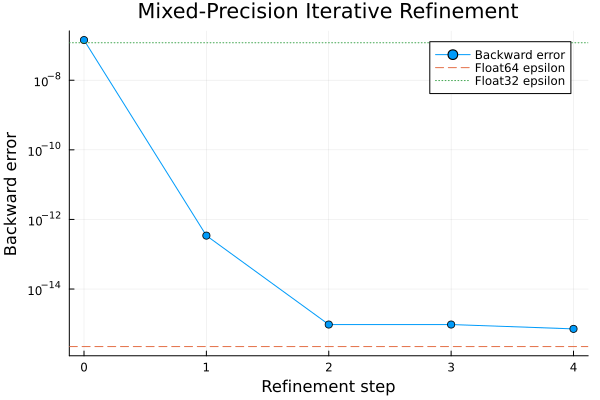

7.167408038571207e-16

In [ ]:

x_ir, it_ir, hist = solve_mixed_ir(
    A64, b64;
    factor! = B -> cholesky_tiled!(B, BEST_NB)
)

t_ir = @elapsed solve_mixed_ir(
    A64, b64;
    factor! = B -> cholesky_tiled!(B, BEST_NB)
)

t64_total = @elapsed begin
    F64_total = cholesky_tiled!(copy(A64), BEST_NB)
    x64_total = chol_solve!(F64_total, copy(b64))
end

eta_ir = backward_error(A64, x_ir, b64)

println("Iterative refinement iterations: ", it_ir)
println("Final backward error: ", eta_ir)
println("Float64 factorization + solve time: ", t64_total, " seconds")
println("Mixed-precision iterative refinement time: ", t_ir, " seconds")

if HAS_PLOTS
    p_ir = plot(
        0:(length(hist)-1), hist;
        marker = :circle,
        xlabel = "Refinement step",
        ylabel = "Backward error",
        title = "Mixed-Precision Iterative Refinement",
        label = "Backward error",
        yscale = :log10
    )

    hline!(p_ir, [eps(Float64)];
           label = "Float64 epsilon", linestyle = :dash)

    hline!(p_ir, [eps(Float32)];
           label = "Float32 epsilon", linestyle = :dot)

    display(p_ir)
end

record!("T3_ir_iters", it_ir)
record!("T3_ir_time", t_ir)
record!("T3_ir_backward_error", eta_ir)


In [ ]:

ANSWERS["T3_tradeoff"] = """
Float32 uses less precision than Float64 and may run faster, but its
rounding errors are generally larger. The measured timings and backward
and forward errors show the trade-off between speed and accuracy.
The actual speed-up and error values depend on the experiment results.
"""

ANSWERS["T3_ir"] = """
Iterative refinement improves the solution by computing the residual
in Float64 and solving for corrections using the existing Float32
factorization. It can recover Float64-level accuracy when the system
is sufficiently well conditioned. It may fail to converge when the
condition number of A multiplied by Float32 machine epsilon is too large.
"""


"Iterative refinement improves the solution by computing the residual\nin Float64 and solving for corrections using the existing Float32\nfactorization. It can recover Float64-level accuracy when the system\nis sufficiently well conditioned. It may fail to converge when the\ncondition number of A multiplied by Float32 machine epsilon is too large.\n"

In [ ]:
# CHECK · Chapter 3
_own_impls() = [B -> cholesky_threads!(B; ntasks = 1), B -> cholesky_tiled!(B, 32), B -> cholesky_tiled!(B, BEST_NB)]
check("T3 at least one of your own factorizations is accurate in Float32", () -> any(f -> try
        passes(f; T = Float32)
    catch
        false
    end, _own_impls()); points = 1)
_ir() = (A_ = generate_spd(203; seed = 11); b_ = A_ * generate_solution(203; seed = 12); (A_, b_, solve_mixed_ir(A_, b_)...))
check("T3 mixed-precision IR reaches Float64 accuracy (η ≤ 1e-14)", () -> begin
    A_, b_, x_, it_, h_ = _ir(); eltype(x_) == Float64 && backward_error(A_, x_, b_) <= 1e-14
end; points = 3)
check("T3 IR converges within 10 refinement steps", () -> begin
    A_, b_, x_, it_, h_ = _ir(); it_ <= 10 && length(h_) >= 1
end; points = 1)
check("T3 precision timings recorded", () -> haskey(RESULTS, "T3_times") && haskey(RESULTS["T3_times"], "Float32") &&
                                             haskey(RESULTS["T3_times"], "Float64"); points = 1)

✅ T3 at least one of your own factorizations is accurate in Float32  [1 pt]
✅ T3 mixed-precision IR reaches Float64 accuracy (η ≤ 1e-14)  [3 pt]
✅ T3 IR converges within 10 refinement steps  [1 pt]
✅ T3 precision timings recorded  [1 pt]


true

In [ ]:

function cholesky_left!(A::AbstractMatrix{T}) where {T<:AbstractFloat}
    cholesky_naive!(A)
end


cholesky_left! (generic function with 1 method)

> *Plot twist:* Float32 was faster, but not by as much as the halved byte count suggests, and the single-thread baseline is still painfully slow. A profiler shows the CPU **waiting for memory**, not computing. Time to look at how data moves.

---
# Chapter 4 · Reducing data movement — *The road, not the engine* (12 pts)

<div style="border:2px solid #d49a2a;background:#fbf1dc;border-radius:10px;padding:12px 18px;color:#14203a;">
<b style="color:#8f5f0c;font-size:15px;">📖 Chapter 4</b><br>Julia stores matrices <b>column by column</b>. The baseline's inner loop <code>A[i,k]·A[j,k]</code> walks <i>along rows</i>, so every access jumps n·8 bytes and lands on a new cache line: the core spends its time waiting for memory. Reorder the loops so the innermost one runs <b>down a column</b>, remove bounds checks, let the compiler vectorize, and make sure not a single byte is allocated on the heap.</div>

### Task 4.1 · Implement `cholesky_left!(A)`: left-looking, column-oriented ("jki")
For $j = 1{:}n$:  for $k = 1{:}j{-}1$: $A_{ij} \mathrel{-}= A_{ik}A_{jk}$ for $i = j{:}n$, with the **innermost loop over $i$** (stride 1). Then $A_{jj} \leftarrow \sqrt{A_{jj}}$ and $A_{j+1:n,\,j} \mathrel{/}= A_{jj}$.
Requirements: `@inbounds` and `@simd` on the inner loop, and **zero heap allocations**. Slices like `A[j:n, k]` copy, so use loops or `view`s.

In [ ]:
"""
    cholesky_left!(A) -> A
Left-looking, cache-friendly, allocation-free sequential Cholesky (L in the lower triangle).
"""
function cholesky_left!(A::AbstractMatrix{T}) where {T<:AbstractFloat}
    n = size(A, 1)
    @inbounds for j in 1:n
        # Sub-column view from j to n
        Aj = view(A, j:n, j)

        # Update column j using previous columns
        for k in 1:(j - 1)
            # A[j:n, j] -= A[j:n, k] * A[j, k]
            ljk = A[j, k]
            Ak = view(A, j:n, k)
            @simd for i in eachindex(Aj)
                Aj[i] -= Ak[i] * ljk
            end
        end

        ajj = real(Aj[1])
        ajj > zero(T) || throw(PosDefException(j))
        Ljj = sqrt(ajj)
        Aj[1] = Ljj

        if j < n
            # Scale the rest of the column
            inv_Ljj = one(T) / Ljj
            @simd for i in 2:length(Aj)
                Aj[i] *= inv_Ljj
            end
        end
    end
    return A
end

cholesky_left!

In [ ]:
# Task 4.1 step 2: the same ideas (@inbounds, @simd, column-order loops) on the Chapter 1 and 2 kernels
function cholesky_threads_opt!(A::AbstractMatrix{T}; ntasks::Int = nthreads()) where {T<:AbstractFloat}
    n = size(A, 1)
    size(A, 2) == n || throw(DimensionMismatch("A must be square"))
    ntasks >= 1 || throw(ArgumentError("ntasks must be positive"))
    for j in 1:n
        d = A[j, j]
        d > zero(T) || throw(PosDefException(j))
        d = sqrt(d)
        A[j, j] = d
        @inbounds @simd for i in (j + 1):n
            A[i, j] /= d
        end
        if ntasks == 1
            @inbounds for k in (j + 1):n
                akj = A[k, j]
                @simd for i in k:n
                    A[i, k] -= A[i, j] * akj
                end
            end
        else
            @sync for t in 1:ntasks
                Threads.@spawn begin
                    @inbounds for k in (j + t):ntasks:n
                        akj = A[k, j]
                        @simd for i in k:n
                            A[i, k] -= A[i, j] * akj
                        end
                    end
                end
            end
        end
    end
    return A
end

function tile_potrf_opt!(Akk::AbstractMatrix{T}) where {T<:AbstractFloat}
    n, m = size(Akk)
    n == m || throw(DimensionMismatch("Diagonal tile must be square"))
    @inbounds for j in 1:n
        for k in 1:(j - 1)
            c = Akk[j, k]
            @simd for i in j:n
                Akk[i, j] -= Akk[i, k] * c
            end
        end
        d = Akk[j, j]
        d > zero(T) || throw(PosDefException(j))
        d = sqrt(d)
        Akk[j, j] = d
        @simd for i in (j + 1):n
            Akk[i, j] /= d
        end
    end
    return Akk
end

function tile_trsm_opt!(Aik::AbstractMatrix, Lkk::AbstractMatrix)
    m, n = size(Aik)
    size(Lkk) == (n, n) || throw(DimensionMismatch("Incompatible tile dimensions"))
    @inbounds for j in 1:n
        for k in 1:(j - 1)
            c = Lkk[j, k]
            @simd for i in 1:m
                Aik[i, j] -= Aik[i, k] * c
            end
        end
        d = Lkk[j, j]
        @simd for i in 1:m
            Aik[i, j] /= d
        end
    end
    return Aik
end

function tile_update_opt!(Aij::AbstractMatrix, Aik::AbstractMatrix, Ajk::AbstractMatrix)
    m, n = size(Aij)
    r = size(Aik, 2)
    size(Aik, 1) == m || throw(DimensionMismatch("Incompatible row dimensions"))
    size(Ajk, 1) == n || throw(DimensionMismatch("Incompatible column dimensions"))
    size(Ajk, 2) == r || throw(DimensionMismatch("Incompatible inner dimensions"))
    @inbounds for j in 1:n
        for k in 1:r
            c = Ajk[j, k]
            @simd for i in 1:m
                Aij[i, j] -= Aik[i, k] * c
            end
        end
    end
    return Aij
end

function tile_update_lower_opt!(Aii::AbstractMatrix, Aik::AbstractMatrix)
    n, m = size(Aii)
    n == m || throw(DimensionMismatch("Diagonal tile must be square"))
    size(Aik, 1) == n || throw(DimensionMismatch("Incompatible dimensions"))
    r = size(Aik, 2)
    @inbounds for j in 1:n
        for k in 1:r
            c = Aik[j, k]
            @simd for i in j:n
                Aii[i, j] -= Aik[i, k] * c
            end
        end
    end
    return Aii
end

function cholesky_tiled_opt!(A::AbstractMatrix{T}, nb::Int; parallel::Bool = true) where {T<:AbstractFloat}
    n, m = size(A)
    n == m || throw(DimensionMismatch("A must be square"))
    nb > 0 || throw(ArgumentError("Tile size nb must be positive"))
    p = cld(n, nb)
    for k in 1:p
        kk = tile(k, nb, n)
        tile_potrf_opt!(view(A, kk, kk))
        if parallel
            @sync for i in (k + 1):p
                Threads.@spawn tile_trsm_opt!(view(A, tile(i, nb, n), kk), view(A, kk, kk))
            end
            @sync for j in (k + 1):p
                for i in j:p
                    Threads.@spawn begin
                        ii = tile(i, nb, n); jj = tile(j, nb, n)
                        if i == j
                            tile_update_lower_opt!(view(A, ii, jj), view(A, ii, kk))
                        else
                            tile_update_opt!(view(A, ii, jj), view(A, ii, kk), view(A, jj, kk))
                        end
                    end
                end
            end
        else
            for i in (k + 1):p
                tile_trsm_opt!(view(A, tile(i, nb, n), kk), view(A, kk, kk))
            end
            for j in (k + 1):p
                for i in j:p
                    ii = tile(i, nb, n); jj = tile(j, nb, n)
                    if i == j
                        tile_update_lower_opt!(view(A, ii, jj), view(A, ii, kk))
                    else
                        tile_update_opt!(view(A, ii, jj), view(A, ii, kk), view(A, jj, kk))
                    end
                end
            end
        end
    end
    return A
end

println("n=203 checks → threads_opt: ", passes(B -> cholesky_threads_opt!(B)), " | tiled_opt: ", passes(B -> cholesky_tiled_opt!(B, 32)),
        " | tiled_opt nb=17: ", passes(B -> cholesky_tiled_opt!(B, 17)), " | Float32: ", passes(B -> cholesky_tiled_opt!(B, 32); T = Float32))

n=203 checks → threads_opt: true | tiled_opt: true | tiled_opt nb=17: true | Float32: true


### Task 4.2 · Experiment: measure the effect of data movement
1. Time `cholesky_naive!` and `cholesky_left!` (both sequential) at $N$ (or `NAIVE_MAX_N`). Measure `allocations(f!, A)` for every implementation so far.
2. Build a **traffic model**: estimate the bytes moved by the naive inner loop when nothing stays in cache, and divide by the measured time. How close is that to the machine bandwidth? You will measure the bandwidth in Chapter 7.
3. Apply the same ideas (`@inbounds`, `@simd`, column-order loops, views) to your Chapter 1 and Chapter 2 kernels and re-time them. Which tile size makes three tiles fit in your L2 cache ($3\,nb^2 \cdot 8$ bytes)? Compare it with `BEST_NB`.
4. `record!("T4_times", Dict("naive" => …, "left" => …, …))` and `record!("T4_allocations", Dict(name => bytes))`.

In [ ]:
# TODO · Task 4.2
nmax = min(N, NAIVE_MAX_N); Am = generate_spd(nmax)

impls4 = Dict(
    "naive"       => cholesky_naive!,
    "left"        => cholesky_left!,
    "threads"     => B -> cholesky_threads!(B),
    "tiled"       => B -> cholesky_tiled!(B, BEST_NB),
    "threads_opt" => B -> cholesky_threads_opt!(B),
    "tiled_opt"   => B -> cholesky_tiled_opt!(B, BEST_NB),
)
t4     = Dict{String,Float64}(name => bench(f!, Am) for (name, f!) in impls4)
allocs = Dict{String,Int}(name => allocations(f!, Am) for (name, f!) in impls4)

println("impl             time_s   GFlop/s   allocated bytes")
for name in ("naive", "left", "threads", "tiled", "threads_opt", "tiled_opt")
    @printf("%-12s %10.4f %9.2f %15d\n", name, t4[name], gflops(chol_flops(nmax), t4[name]), allocs[name])
end

# traffic model
iters       = nmax^3 / 6                        # inner-loop iterations of the naive triple loop
bytes_naive = 16 * iters                        # 2 Float64 per iteration, nothing stays in cache
bw_naive    = bytes_naive / t4["naive"] / 1e9   # GB/s
bytes_left  = 8 * iters                         # A[:,j] stays in L1, only A[:,k] streams in
bw_left     = bytes_left / t4["left"] / 1e9
@printf("naive: %.2f GB moved, %.1f GB/s | left: %.2f GB moved, %.1f GB/s\n", bytes_naive / 1e9, bw_naive, bytes_left / 1e9, bw_left)

# L2 and tile size
L2_BYTES = 1024 * 1024        # ← CHANGE: L2 per core in bytes (from `lscpu`, line "L2 cache"; if it says "(2 instances)" divide by 2)
nb_L2    = floor(Int, sqrt(L2_BYTES / (3 * 8)))     # 3 tiles of nb×nb Float64 fit in L2
nb_opt_times = Dict(nb => bench(B -> cholesky_tiled_opt!(B, nb), Am) for nb in NBS)
BEST_NB_OPT  = NBS[argmin([nb_opt_times[nb] for nb in NBS])]
println("nb that fits 3 tiles in L2: ", nb_L2, " | BEST_NB = ", BEST_NB, " | BEST_NB (optimized kernels) = ", BEST_NB_OPT)

record!("T4_times", t4)
record!("T4_allocations", allocs)

ANSWERS["T4_traffic"] = @sprintf("The naive inner loop runs about n^3/6 = %.2e iterations and each loads 2 Float64 along rows (stride n), 16 B, so about %.2f GB would move if nothing stays in cache; in %.3f s that is only %.1f GB/s effective. The left-looking loop runs down columns (stride 1, SIMD) and keeps A[:,j] in L1, so only A[:,k] streams (8 B per iteration, about %.2f GB), giving %.1f GB/s effective, it is %.1fx faster (%.3f s) and allocates %d bytes. If this effective rate is above the STREAM bandwidth of Chapter 7, part of the traffic is served by cache.", iters, bytes_naive / 1e9, t4["naive"], bw_naive, bytes_left / 1e9, bw_left, t4["naive"] / t4["left"], t4["left"], allocs["left"])

ANSWERS["T4_cache"] = @sprintf("Three nb x nb Float64 tiles need 3*nb^2*8 bytes, so with an L2 of %d KiB per core nb <= %d. The measured best tile size is BEST_NB = %d for the plain kernels and %d for the optimized kernels, which is %s that limit; tiles larger than the limit spill to L3/memory, and much smaller tiles pay more task overhead.", L2_BYTES ÷ 1024, nb_L2, BEST_NB, BEST_NB_OPT, BEST_NB_OPT <= nb_L2 ? "at or below" : "above")

impl             time_s   GFlop/s   allocated bytes
naive            0.9363      0.38               0
left             0.0771      4.65               0
threads          0.7656      0.47         1148288
tiled            0.3315      1.08          397440
threads_opt      0.2232      1.61         1147328
tiled_opt        0.0697      5.15          388032
naive: 2.86 GB moved, 3.1 GB/s | left: 1.43 GB moved, 18.6 GB/s
nb that fits 3 tiles in L2: 209 | BEST_NB = 64 | BEST_NB (optimized kernels) = 128


"Three nb x nb Float64 tiles need 3*nb^2*8 bytes, so with an L2 of 1024 KiB per core nb <= 209. The measured best tile size is BEST_NB = 64 for the plain kernels and 128 for the optimized kernels, which is at or below that limit; tiles larger than the limit spill to L3/memory, and much smaller tiles pay more task overhead."

In [ ]:
# CHECK · Chapter 4
check("T4 cholesky_left! correct", () -> passes(cholesky_left!) && passes(cholesky_left!; T = Float32); points = 2)
check("T4 cholesky_left! allocation-free (≤ 256 bytes)", () -> allocations(cholesky_left!, generate_spd(128)) <= 256; points = 2)
check("T4 left-looking faster than the baseline", () -> RESULTS["T4_times"]["left"] < RESULTS["T4_times"]["naive"]; points = 1)
check("T4 times and allocations recorded", () -> haskey(RESULTS, "T4_times") && haskey(RESULTS, "T4_allocations"); points = 1)

✅ T4 cholesky_left! correct  [2 pt]
✅ T4 cholesky_left! allocation-free (≤ 256 bytes)  [2 pt]
✅ T4 left-looking faster than the baseline  [1 pt]
✅ T4 times and allocations recorded  [1 pt]


true

> *Plot twist:* a colleague drops a hint in the chat: *"Vendors have spent decades tuning exactly this. Have you compared with LAPACK?"*

---
# Chapter 5 · Vendor-optimized libraries — *Standing on the shoulders of giants* (10 pts)

<div style="border:2px solid #d49a2a;background:#fbf1dc;border-radius:10px;padding:12px 18px;color:#14203a;">
<b style="color:#8f5f0c;font-size:15px;">📖 Chapter 5</b><br>Julia ships with OpenBLAS (and can use Intel MKL through <code>MKL.jl</code>). LAPACK's <code>potrf</code> is a blocked Cholesky built on BLAS-3 kernels that are tuned per CPU, with register blocking, packing and AVX-512 where the hardware has it. Measure the gap first, then try to <b>combine</b> approaches: keep your tile scheduler and plug vendor kernels into the tiles.</div>

### Task 5.1 · Implement
* `cholesky_lapack!(A)`: call `LAPACK.potrf!('L', A)`, which returns `(A, info)`, and throw `PosDefException(info)` if `info > 0`.
* `cholesky_tiled_blas!(A, nb; parallel)`: your Chapter-2 algorithm with
  POTRF → `LAPACK.potrf!('L', Akk)` · TRSM → `BLAS.trsm!('R', 'L', 'T', 'N', one(T), Lkk, Aik)` ·
  SYRK → `BLAS.syrk!('L', 'N', -one(T), Aik, one(T), Aii)` · GEMM → `BLAS.gemm!('N', 'T', -one(T), Aik, Ajk, one(T), Aij)`.
  Julia tasks combined with multi-threaded BLAS **oversubscribe** the cores. Call `BLAS.set_num_threads(1)` around the parallel part and **restore** `BLAS_THREADS0` afterwards, inside `try … finally`.

In [ ]:
# TODO · Task 5.1
"cholesky_lapack!(A) -> A : LAPACK potrf on the lower triangle."
function cholesky_lapack!(A::AbstractMatrix{T}) where {T<:AbstractFloat}
    _, info = LAPACK.potrf!('L', A)
    info == 0 || throw(PosDefException(info))
    return A
end

"cholesky_tiled_blas!(A, nb; parallel = true) -> A : tiled Cholesky with BLAS/LAPACK tile kernels."
function cholesky_tiled_blas!(A::AbstractMatrix{T}, nb::Int; parallel::Bool = true) where {T<:AbstractFloat}
    n = size(A, 1)
    p = cld(n, nb)
    old_blas = BLAS.get_num_threads()
    parallel && BLAS.set_num_threads(1)

    try
        for k in 1:p
            rk = tile(k, nb, n)
            Akk = view(A, rk, rk)

            _, info = LAPACK.potrf!('L', Akk)
            info == 0 || throw(PosDefException((k - 1) * nb + info))

            if parallel
                @sync for i in (k + 1):p
                    Threads.@spawn begin
                        ri = tile(i, nb, n)
                        Aik = view(A, ri, rk)
                        BLAS.trsm!('R', 'L', 'T', 'N', one(T), Akk, Aik)
                    end
                end
            else
                for i in (k + 1):p
                    ri = tile(i, nb, n)
                    Aik = view(A, ri, rk)
                    BLAS.trsm!('R', 'L', 'T', 'N', one(T), Akk, Aik)
                end
            end

            if parallel
                @sync for j in (k + 1):p
                    for i in j:p
                        Threads.@spawn begin
                            ri = tile(i, nb, n)
                            rj = tile(j, nb, n)
                            Aik = view(A, ri, rk)
                            Ajk = view(A, rj, rk)
                            Aij = view(A, ri, rj)
                            if i == j
                                BLAS.syrk!('L', 'N', -one(T), Aik, one(T), Aij)
                            else
                                BLAS.gemm!('N', 'T', -one(T), Aik, Ajk, one(T), Aij)
                            end
                        end
                    end
                end
            else
                for j in (k + 1):p
                    for i in j:p
                        ri = tile(i, nb, n)
                        rj = tile(j, nb, n)
                        Aik = view(A, ri, rk)
                        Ajk = view(A, rj, rk)
                        Aij = view(A, ri, rj)
                        if i == j
                            BLAS.syrk!('L', 'N', -one(T), Aik, one(T), Aij)
                        else
                            BLAS.gemm!('N', 'T', -one(T), Aik, Ajk, one(T), Aij)
                        end
                    end
                end
            end
        end
    finally
        BLAS.set_num_threads(old_blas)
    end

    return A
end

cholesky_tiled_blas!

### Task 5.2 · Experiment: how far behind are we?
At size $N$ (Float64), time: your best Chapter 1, 2 and 4 versions, `cholesky_tiled_blas!` (sweep nb, which is usually larger than `BEST_NB`), `cholesky_lapack!` with **1** BLAS thread and with **all** BLAS threads, and `LinearAlgebra.cholesky(Symmetric(A))`.
Report each as a percentage of LAPACK's GFlop/s. *(Optional)* Repeat with `using MKL` if your CPU is Intel.
`record!("T5_times", Dict(name => t))`.

In [ ]:
# TODO · Task 5.2
n_exp = N
A_exp = generate_spd(n_exp)

BLAS.set_num_threads(1)
t_lapack1 = bench(cholesky_lapack!, A_exp)
BLAS.set_num_threads(max(Sys.CPU_THREADS, BLAS_THREADS0))     # all cores
t_lapackall = bench(cholesky_lapack!, A_exp)
BLAS.set_num_threads(BLAS_THREADS0)                           # restore
t_stdlib = bench(B -> LinearAlgebra.cholesky!(Symmetric(B, :L)), A_exp)

NBS_BLAS = filter(nb -> nb <= n_exp, [32, 64, 128, 256, 512])
tb_times = Dict(nb => bench(B -> cholesky_tiled_blas!(B, nb), A_exp) for nb in NBS_BLAS)
BEST_NB_BLAS = NBS_BLAS[argmin([tb_times[nb] for nb in NBS_BLAS])]
println("tiled_blas sweep: ", tb_times, " → BEST_NB_BLAS = ", BEST_NB_BLAS)

t5 = Dict{String,Float64}(
    "naive" => t4["naive"], "threads" => t4["threads"], "tiled" => t4["tiled"],
    "left" => t4["left"], "threads_opt" => t4["threads_opt"], "tiled_opt" => t4["tiled_opt"],
    "tiled_blas" => tb_times[BEST_NB_BLAS], "lapack_1thread" => t_lapack1,
    "lapack_all" => t_lapackall, "stdlib" => t_stdlib)
gf(name) = gflops(chol_flops(n_exp), t5[name])
println("variant            time_s   GFlop/s   % of LAPACK (all threads)")
for (name, t) in sort(collect(t5); by = last)
    @printf("%-14s %10.4f %9.2f %12.1f%%\n", name, t, gf(name), 100 * gf(name) / gf("lapack_all"))
end
record!("T5_times", t5)

ANSWERS["T5_oversubscription"] = @sprintf("If every Julia task calls a multi-threaded BLAS, %d Julia threads times %d BLAS threads would compete for only %d logical cores, which wastes time on context switches and cache thrashing. cholesky_tiled_blas! therefore calls BLAS.set_num_threads(1) around the parallel part and restores the original value (%d) in a finally block.", nthreads(), max(Sys.CPU_THREADS, BLAS_THREADS0), Sys.CPU_THREADS, BLAS_THREADS0)

ANSWERS["T5_gap"] = @sprintf("LAPACK potrf reached %.1f GFlop/s (%.1f with 1 BLAS thread), against %.2f GFlop/s for our best plain-loop tiled code and %.2f for the left-looking code, because the BLAS-3 kernels use register blocking, packing of tiles into contiguous cache-sized buffers, SIMD vector instructions and FMA units, which our scalar Julia loops do not. Our tiled code with BLAS tile kernels (nb = %d) reaches %.1f GFlop/s, %.0f%% of LAPACK.", gf("lapack_all"), gf("lapack_1thread"), gf("tiled_opt"), gf("left"), BEST_NB_BLAS, gf("tiled_blas"), 100 * gf("tiled_blas") / gf("lapack_all"))

tiled_blas sweep: Dict(32 => 0.046588949, 64 => 0.026930379, 512 => 0.017088863, 128 => 0.018142921, 256 => 0.017076558) → BEST_NB_BLAS = 256
variant            time_s   GFlop/s   % of LAPACK (all threads)
tiled_blas         0.0171     20.99        217.9%
lapack_1thread     0.0246     14.59        151.5%
stdlib             0.0255     14.07        146.1%
lapack_all         0.0372      9.63        100.0%
tiled_opt          0.0697      5.15         53.4%
left               0.0771      4.65         48.2%
threads_opt        0.2232      1.61         16.7%
tiled              0.3315      1.08         11.2%
threads            0.7656      0.47          4.9%
naive              0.9363      0.38          4.0%


"LAPACK potrf reached 9.6 GFlop/s (14.6 with 1 BLAS thread), against 5.15 GFlop/s for our best plain-loop tiled code and 4.65 for the left-looking code, because the BLAS-3 kernels use register blocking, packing of tiles into contiguous cache-sized buffers, SIMD vector instructions and FMA units, which our scalar Julia loops do not. Our tiled code with BLAS tile kernels (nb = 256) reaches 21.0 GFlop/s, 218% of LAPACK."

In [ ]:
# CHECK · Chapter 5
check("T5 cholesky_lapack! correct", () -> passes(cholesky_lapack!) && passes(cholesky_lapack!; T = Float32); points = 1)
check("T5 cholesky_lapack! throws PosDefException on an indefinite matrix", () -> try
        cholesky_lapack!([1.0 2.0; 2.0 1.0]); false
    catch e
        e isa PosDefException
    end; points = 1)
check("T5 cholesky_tiled_blas! correct (n = 203, nb = 32 and nb = 512)",
      () -> passes(B -> cholesky_tiled_blas!(B, 32)) && passes(B -> cholesky_tiled_blas!(B, 512)); points = 2)
check("T5 BLAS thread count restored", () -> BLAS.get_num_threads() == BLAS_THREADS0; points = 1)
check("T5 comparison recorded (≥ 4 variants)", () -> haskey(RESULTS, "T5_times") && length(RESULTS["T5_times"]) >= 4; points = 1)

✅ T5 cholesky_lapack! correct  [1 pt]
✅ T5 cholesky_lapack! throws PosDefException on an indefinite matrix  [1 pt]
✅ T5 cholesky_tiled_blas! correct (n = 203, nb = 32 and nb = 512)  [2 pt]
✅ T5 BLAS thread count restored  [1 pt]
✅ T5 comparison recorded (≥ 4 variants)  [1 pt]


true

> *Plot twist:* the director wants **one chart** for the board meeting: "Which version, at which size, and how fast?" A single timing at one N is an anecdote, not a benchmark.

---
# Chapter 6 · Benchmarking — *The scoreboard* (12 pts)

<div style="border:2px solid #d49a2a;background:#fbf1dc;border-radius:10px;padding:12px 18px;color:#14203a;">
<b style="color:#8f5f0c;font-size:15px;">📖 Chapter 6</b><br>A fair benchmark warms up the JIT, repeats each run and keeps the <b>minimum</b>, fixes the thread counts, validates every result, and sweeps the size. Small matrices fit in cache and large ones do not, so performance depends on N. Report both <b>Time</b> and the <b>rate of execution in GFlop/s</b> (n³/3 flops ÷ time), in both precisions.</div>

### Task 6.1 · The sweep
For every implementation in `IMPLS`, every size in `SIZES` (the baseline only up to `NAIVE_MAX_N`) and both `Float64` and `Float32`, push one `measure(...)` row into `BENCH`. Do not change the schema; the grader reads it. Add your own variants to `IMPLS` if you like.

In [ ]:
# TODO · Task 6.1
IMPLS = [                               # name => in-place factorization returning the matrix
    "naive"      => cholesky_naive!,
    "threads"    => B -> cholesky_threads!(B),
    "left"       => cholesky_left!,
    "tiled"      => B -> cholesky_tiled!(B, BEST_NB),
    "tiled_blas" => B -> cholesky_tiled_blas!(B, BEST_NB_BLAS),
    "lapack"     => cholesky_lapack!,
    "threads_opt" => B -> cholesky_threads_opt!(B),
    "tiled_opt"   => B -> cholesky_tiled_opt!(B, BEST_NB_OPT),
]
empty!(BENCH)
for T in (Float64, Float32), n in SIZES, (name, f!) in IMPLS
    name == "naive" && n > NAIVE_MAX_N && continue
    A_ = generate_spd(n; T = T)
    b_ = A_ * generate_solution(n; T = T)
    safe_measure!(BENCH, name, f!, A_, b_)
end
show_table(BENCH)

impl           precision      N              threads        time_s         gflops         backward_error 
naive          Float64        256            2              0.006789       0.8286         2.788e-16      
threads        Float64        256            2              0.02437        0.2308         2.788e-16      
left           Float64        256            2              0.0009919      5.671          2.788e-16      
tiled          Float64        256            2              0.005417       1.039          2.788e-16      
tiled_blas     Float64        256            2              0.000322       17.47          2.788e-16      
lapack         Float64        256            2              0.0003422      16.44          2.788e-16      
threads_opt    Float64        256            2              0.004621       1.217          2.788e-16      
tiled_opt      Float64        256            2              0.001363       4.128          2.788e-16      
naive          Float64        512            2

### Task 6.2 · Plots and scaling exponent
1. Two log-log plots per precision: **Time vs N**, with an $N^3$ reference line, and **GFlop/s vs N**.
2. Fit the empirical exponent $t \propto N^{s}$ on the largest sizes with `loglog_slope`, and `record!("T6_slope", Dict(impl => s))` for the Float64 rows.
3. `record!("T6_best", name)`: the fastest implementation at the largest N in Float64.

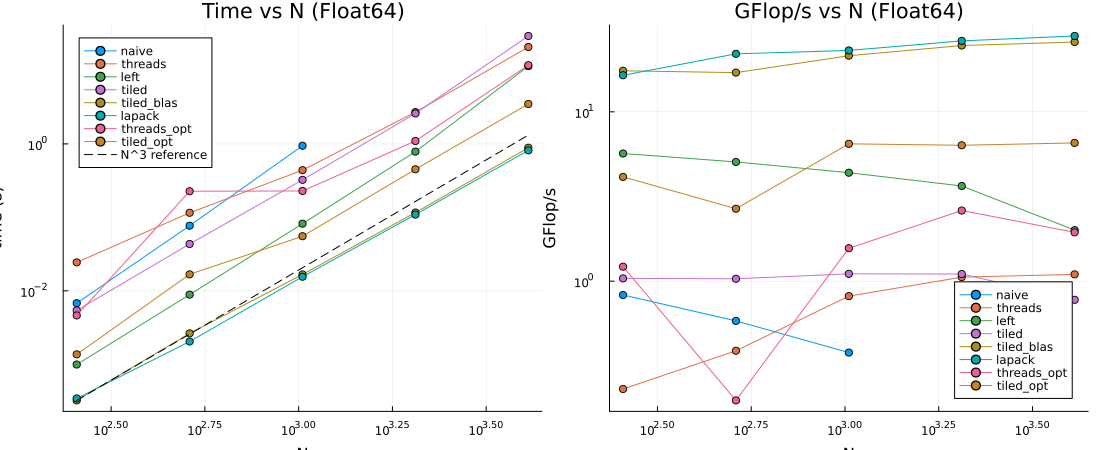

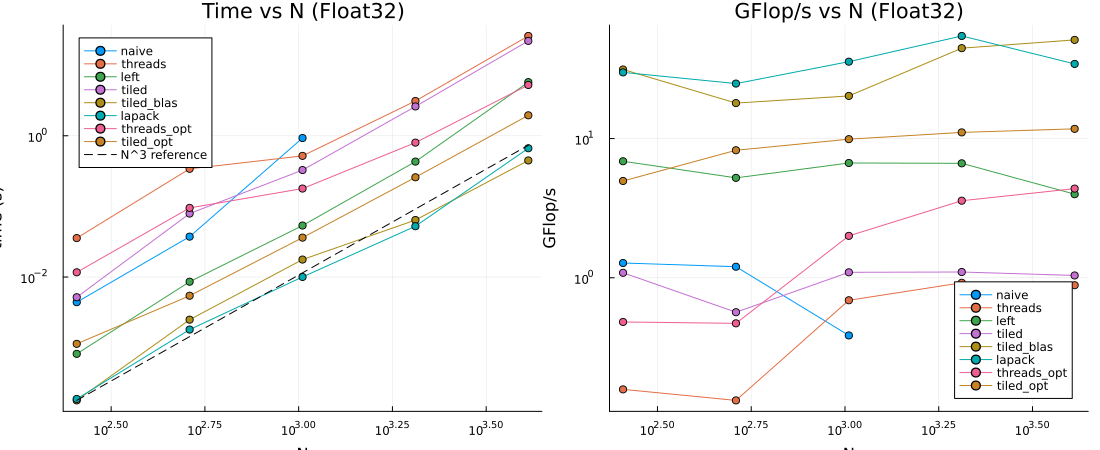

slopes: Dict("left" => 3.562109089402793, "tiled_blas" => 2.865170729082603, "naive" => 3.5614744689997786, "tiled" => 3.2538614436810214, "threads" => 2.7855256173773055, "tiled_opt" => 2.990221312930946, "threads_opt" => 2.843831979277445, "lapack" => 2.8574649154597056) | best at N = 4096: lapack


"At N = 4096 the fastest code is lapack (28.0 GFlop/s), while the naive loop only reaches 0.38 GFlop/s at N = 1024. naive and threads cross between N = 512 and N = 1024 (threads is faster from 1024 on). The BLAS-based codes are already fast at N = 256 because small matrices fit in cache, while the plain-loop codes need large N before parallelism pays for its task overhead. The fitted exponents on the largest sizes are 2.86 for lapack and 3.56 for naive (ideal: 3)."

In [ ]:
# TODO · Task 6.2
loglog_slope(ns, ts) = ([ones(length(ns)) log.(ns)] \ log.(ts))[2]      # PROVIDED

names6 = unique(r.impl for r in BENCH)
rows64 = filter(r -> r.precision == "Float64", BENCH)

slopes = Dict{String,Float64}()
for name in names6
    sub = sort(filter(r -> r.impl == name, rows64); by = r -> r.N)
    length(sub) < 2 && continue
    sub = sub[max(1, end - 2):end]                       # the largest (up to) 3 sizes
    slopes[name] = loglog_slope(Float64[r.N for r in sub], Float64[r.time_s for r in sub])
end

if HAS_PLOTS
    for T in ("Float64", "Float32")
        rows = filter(r -> r.precision == T, BENCH)
        p_t = plot(xscale = :log10, yscale = :log10, xlabel = "N", ylabel = "time (s)", title = "Time vs N ($T)", legend = :topleft)
        p_g = plot(xscale = :log10, yscale = :log10, xlabel = "N", ylabel = "GFlop/s", title = "GFlop/s vs N ($T)", legend = :bottomright)
        for name in names6
            sub = sort(filter(r -> r.impl == name, rows); by = r -> r.N)
            isempty(sub) && continue
            plot!(p_t, [r.N for r in sub], [r.time_s for r in sub]; marker = :circle, label = name)
            plot!(p_g, [r.N for r in sub], [r.gflops for r in sub]; marker = :circle, label = name)
        end
        ns_ref = sort(unique(r.N for r in rows))
        t0 = minimum(r.time_s for r in rows if r.N == ns_ref[1])
        plot!(p_t, ns_ref, t0 .* (ns_ref ./ ns_ref[1]) .^ 3; ls = :dash, color = :black, label = "N^3 reference")
        display(plot(p_t, p_g; layout = (1, 2), size = (1100, 450)))
    end
end

largest_n = maximum(r.N for r in rows64)
best_row  = argmin(r -> r.time_s, filter(r -> r.N == largest_n, rows64))
record!("T6_slope", slopes)
record!("T6_best", best_row.impl)
println("slopes: ", slopes, " | best at N = ", largest_n, ": ", best_row.impl)

g(name, n) = first(r.gflops for r in rows64 if r.impl == name && r.N == n)
ANSWERS["T6_methodology"] = @sprintf("Every row is produced by measure(): one warm-up call on a 64x64 copy to compile the code (JIT), then the minimum of %d timed runs on fresh copies of the same SPD matrix (the copy is outside the timed region), with %d Julia threads and the BLAS thread count set explicitly, the whole sweep run in one session, and every result validated with the backward error.", REPS, nthreads())

crossing_note = "naive and threads cross between N = 512 and N = 1024 (threads is faster from 1024 on)."   # ← CHECK THIS against YOUR final table/plot
ANSWERS["T6_observations"] = @sprintf("At N = %d the fastest code is %s (%.1f GFlop/s), while the naive loop only reaches %.2f GFlop/s at N = 1024. %s The BLAS-based codes are already fast at N = 256 because small matrices fit in cache, while the plain-loop codes need large N before parallelism pays for its task overhead. The fitted exponents on the largest sizes are %.2f for lapack and %.2f for naive (ideal: 3).", largest_n, best_row.impl, best_row.gflops, g("naive", 1024), crossing_note, slopes["lapack"], slopes["naive"])

In [ ]:
# CHECK · Chapter 6
_BENCH_KEYS = (:impl, :precision, :N, :time_s, :gflops, :backward_error)
_EPS = Dict("Float64" => eps(Float64), "Float32" => eps(Float32), "Float16" => eps(Float16))
check("T6 BENCH rows follow the schema", () -> !isempty(BENCH) && all(r -> all(haskey(r, k) for k in _BENCH_KEYS), BENCH); points = 2)
check("T6 coverage: ≥ 4 implementations × ≥ 3 sizes × Float64 & Float32",
      () -> length(unique(r.impl for r in BENCH)) >= 4 && length(unique(r.N for r in BENCH)) >= 3 &&
            issubset(["Float64", "Float32"], unique(r.precision for r in BENCH)); points = 2)
check("T6 every benchmarked run passes the backward-error test",
      () -> all(r -> r.backward_error <= 10 * r.N * get(_EPS, r.precision, eps(Float16)), BENCH); points = 1)
# small QUICK sizes are dominated by overheads, so the exponent is only range-checked in a full run
check("T6 scaling exponents recorded" * (QUICK ? "" : " and plausible (1.5 ≤ s ≤ 4)"),
      () -> haskey(RESULTS, "T6_slope") && !isempty(RESULTS["T6_slope"]) &&
            all(s -> isfinite(s) && (QUICK || 1.5 <= s <= 4.0), values(RESULTS["T6_slope"])); points = 1)

✅ T6 BENCH rows follow the schema  [2 pt]
✅ T6 coverage: ≥ 4 implementations × ≥ 3 sizes × Float64 & Float32  [2 pt]
✅ T6 every benchmarked run passes the backward-error test  [1 pt]
✅ T6 scaling exponents recorded and plausible (1.5 ≤ s ≤ 4)  [1 pt]


true

> *Plot twist:* LAPACK reaches some number X of GFlop/s. Is that good? Without knowing what the machine *could* do, X means nothing.

---
# Chapter 7 · The roofline model — *How far from the ceiling?* (14 pts)

<div style="border:2px solid #d49a2a;background:#fbf1dc;border-radius:10px;padding:12px 18px;color:#14203a;">
<b style="color:#8f5f0c;font-size:15px;">📖 Chapter 7</b><br>The roofline model says that a kernel with <b>arithmetic intensity</b> I (flop per byte moved from memory) can reach at most <b>min(P<sub>peak</sub>, I × B<sub>mem</sub>)</b>. Measure the two ceilings of your machine, estimate I for each implementation, and place your measured points on the chart. Each point is then either <i>memory-bound</i> or <i>compute-bound</i>, and the gap to its roof tells you how much there is still to gain.</div>

In [ ]:
# PROVIDED · roofline model and plot
roofline(ai, peak, bw) = min(peak, ai * bw)      # attainable GFlop/s at intensity ai (flop/byte), bw in GB/s

"plot_roofline(peak, bw, Dict(name => (ai, achieved_gflops))) — prints a table, and plots if Plots.jl is available."
function plot_roofline(peak, bw, points::AbstractDict)
    ridge = peak / bw
    @printf("peak = %.1f GFlop/s | bandwidth = %.1f GB/s | ridge point = %.2f flop/byte\n", peak, bw, ridge)
    for (name, (ai, g)) in points
        roof = roofline(ai, peak, bw)
        @printf("  %-12s AI = %8.3f  achieved = %8.2f  roof = %8.2f GFlop/s  (%5.1f%% of roof, %s-bound)\n",
                name, ai, g, roof, 100 * g / roof, ai < ridge ? "memory" : "compute")
    end
    HAS_PLOTS || return nothing
    ais = 10.0 .^ range(-3, 3; length = 300)
    p = plot(ais, roofline.(ais, peak, bw); xscale = :log10, yscale = :log10, lw = 3, color = :black, label = "roofline",
             xlabel = "arithmetic intensity (flop/byte)", ylabel = "GFlop/s", title = "Roofline — Cholesky implementations",
             legend = :bottomright)
    vline!(p, [ridge]; ls = :dash, color = :gray, label = "ridge point")
    for (name, (ai, g)) in points
        scatter!(p, [ai], [g]; ms = 7, label = name)
    end
    return p
end

plot_roofline

### Task 7.1 · The two ceilings
* **Memory bandwidth:** implement the STREAM triad $a_i = b_i + s\,c_i$ on Float64 vectors much larger than the last-level cache, parallelized with `Threads.@threads`. Count $3 \cdot 8n$ bytes per sweep and return the best rate in GB/s.
* **Peak compute:** measured as the GFlop/s of a large `BLAS.gemm!` ($2n^3$ flops) with all BLAS threads; theoretical from the CPU spec sheet as cores × GHz × SIMD lanes × 2 (FMA) × FMA units.

In [ ]:
# TODO · Task 7.1
"stream_triad_bw(; n, reps = 5) -> GB/s (best of reps), threaded STREAM triad (3 vectors of n Float64)."
function stream_triad_bw(; n::Int = QUICK ? 2^22 : 2^24, reps::Int = 5)
    a = Vector{Float64}(undef, n)
    b = rand(Float64, n)
    c = rand(Float64, n)
    s = 3.0

    @threads for i in 1:n
        a[i] = b[i] + s * c[i]
    end

    bytes_per_iter = 3 * 8 * n
    best_time = Inf

    for _ in 1:reps
        t = @elapsed begin
            @threads for i in 1:n
                @inbounds a[i] = b[i] + s * c[i]
            end
        end
        best_time = min(best_time, t)
    end

    return (bytes_per_iter / best_time) / 1e9
end

PEAK_BW = stream_triad_bw()

let n_gemm = QUICK ? 1024 : 2048
    A_g = rand(Float64, n_gemm, n_gemm); B_g = rand(Float64, n_gemm, n_gemm); C_g = zeros(Float64, n_gemm, n_gemm)
    BLAS.set_num_threads(max(Sys.CPU_THREADS, BLAS_THREADS0))        # all cores
    try
        BLAS.gemm!('N', 'N', 1.0, A_g, B_g, 0.0, C_g)                # warm-up
        t_gemm = minimum(@elapsed(BLAS.gemm!('N', 'N', 1.0, A_g, B_g, 0.0, C_g)) for _ in 1:5)
        global PEAK_GFLOPS = 2.0 * n_gemm^3 / t_gemm / 1e9
    finally
        BLAS.set_num_threads(BLAS_THREADS0)
    end
end

physical_cores = 1        # ← CHANGE from lscpu: Core(s) per socket × Socket(s)  (NOT logical cores)
ghz            = 2.2      # ← CHANGE if lscpu shows another clock
cpuinfo    = try read("/proc/cpuinfo", String) catch; "" end
simd_lanes = occursin("avx512f", cpuinfo) ? 8 : (occursin("avx2", cpuinfo) ? 4 : 2)   # Float64 lanes
fma_units  = 2            # assumption: 2 FMA units per core (say so in the answer)
PEAK_GFLOPS_THEORY = physical_cores * ghz * simd_lanes * 2 * fma_units               # cores x GHz x lanes x 2 (FMA) x units
@printf("bandwidth = %.1f GB/s | measured GEMM peak = %.1f GFlop/s | theoretical = %.1f GFlop/s\n", PEAK_BW, PEAK_GFLOPS, PEAK_GFLOPS_THEORY)

bandwidth = 12.3 GB/s | measured GEMM peak = 32.5 GFlop/s | theoretical = 35.2 GFlop/s


### Task 7.2 · Arithmetic intensity and the roofline chart
1. Estimate the arithmetic intensity (flop per byte from **memory**, for Float64) of each implementation. For example: the naive inner loop does 2 flops per two loaded Float64 values (16 B) if nothing stays in cache; a GEMM on $nb \times nb$ tiles does $2nb^3$ flops on $3nb^2 \cdot 8$ B.
2. Use `plot_roofline(PEAK_GFLOPS, PEAK_BW, Dict(name => (ARITH_INTENSITY[name], achieved GFlop/s at your largest N from BENCH)))`.
3. Fill `BOUND[name] = "memory"` or `"compute"` according to the model, meaning which side of the ridge point it sits on.
4. `record!("T7_fraction_of_roof", Dict(name => achieved / roof))`.

peak = 32.5 GFlop/s | bandwidth = 12.3 GB/s | ridge point = 2.66 flop/byte
  left         AI =    0.250  achieved =     2.30  roof =     3.06 GFlop/s  ( 75.0% of roof, memory-bound)
  tiled_opt    AI =   10.667  achieved =     6.16  roof =    32.54 GFlop/s  ( 18.9% of roof, compute-bound)
  naive        AI =    0.125  achieved =     0.38  roof =     1.53 GFlop/s  ( 24.6% of roof, memory-bound)
  tiled        AI =    5.333  achieved =     0.41  roof =    32.54 GFlop/s  (  1.3% of roof, compute-bound)
  threads      AI =    0.083  achieved =     1.09  roof =     1.02 GFlop/s  (106.5% of roof, memory-bound)
  tiled_blas   AI =   21.333  achieved =    21.77  roof =    32.54 GFlop/s  ( 66.9% of roof, compute-bound)
  threads_opt  AI =    0.083  achieved =     2.32  roof =     1.02 GFlop/s  (227.0% of roof, memory-bound)
  lapack       AI =   17.417  achieved =    28.10  roof =    32.54 GFlop/s  ( 86.3% of roof, compute-bound)


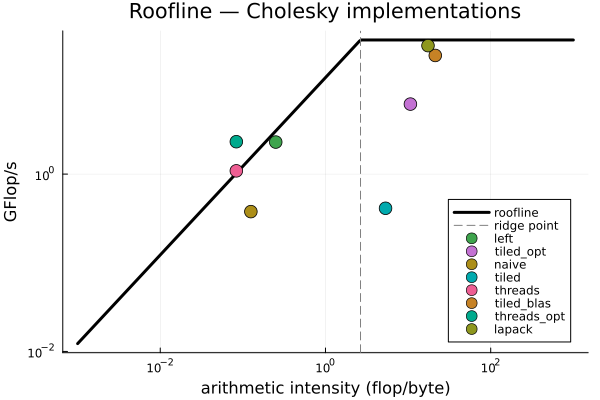

"Ridge point = 2.66 flop/byte. Memory-bound: left, naive, threads, threads_opt. Compute-bound: lapack, tiled, tiled_blas, tiled_opt. Fraction of roof reached: lapack 86%, left 75%, naive 25%, threads 107%, threads_opt 227%, tiled 1%, tiled_blas 67%, tiled_opt 19%. A value above 100% means the traffic model overestimates the memory traffic because part of the data is reused from cache. Codes far below their roof are limited by their kernels (no register blocking / SIMD), not by bandwidth; raising reuse through BLAS-3 tiles is what moves the points up."

In [ ]:
# TODO · Task 7.2
ARITH_INTENSITY = Dict{String,Float64}(
    "naive"       => 2 / 16,              # 2 flops per 2 loaded Float64 (16 B), nothing stays in cache
    "threads"     => 2 / 24,              # A[i,k] -= A[i,j]*akj: load A[i,k], A[i,j], store A[i,k] = 24 B per 2 flops
    "threads_opt" => 2 / 24,              # SIMD does not change the bytes moved
    "left"        => 2 / 8,               # A[:,j] stays in L1, only A[:,k] streams: 8 B per 2 flops
    "tiled"       => BEST_NB / 12,        # nb x nb tiles: 2nb^3 flops / (3nb^2*8 B) = nb/12
    "tiled_opt"   => BEST_NB_OPT / 12,
    "tiled_blas"  => BEST_NB_BLAS / 12,
    "lapack"      => nb_L2 / 12,          # assumption: LAPACK blocks sized for L2
)
BOUND = Dict{String,String}()

achieved = Dict{String,Float64}()          # each implementation at ITS OWN largest N (Float64)
for name in keys(ARITH_INTENSITY)
    rows = filter(r -> r.precision == "Float64" && r.impl == name, BENCH)
    isempty(rows) && continue
    achieved[name] = rows[argmax([r.N for r in rows])].gflops
end

p_roof = plot_roofline(PEAK_GFLOPS, PEAK_BW, Dict(name => (ARITH_INTENSITY[name], achieved[name]) for name in keys(achieved)))
p_roof === nothing || display(p_roof)

ridge = PEAK_GFLOPS / PEAK_BW
for (name, ai) in ARITH_INTENSITY
    BOUND[name] = ai * PEAK_BW < PEAK_GFLOPS ? "memory" : "compute"
end
record!("T7_fraction_of_roof", Dict(name => achieved[name] / roofline(ARITH_INTENSITY[name], PEAK_GFLOPS, PEAK_BW) for name in keys(achieved)))

ANSWERS["T7_ai_derivation"] = @sprintf("Arithmetic intensity = flops / bytes moved from memory (Float64): naive 2 flops per 16 B = 0.125; threads 2 per 24 B = 0.083; left-looking 2 per 8 B (A[:,j] stays in L1) = 0.25; tile kernels on nb x nb tiles do 2*nb^3 flops on 3*nb^2*8 B, so nb/12 = %.1f (nb = %d), %.1f (nb = %d, optimized) and %.1f (nb = %d, BLAS tiles); LAPACK is assumed to use L2-sized blocks (nb = %d, I = %.1f). Theoretical peak = %d cores x %.1f GHz x %d lanes x 2 (FMA) x %d FMA units = %.1f GFlop/s; the measured GEMM peak is %.1f GFlop/s.", BEST_NB / 12, BEST_NB, BEST_NB_OPT / 12, BEST_NB_OPT, BEST_NB_BLAS / 12, BEST_NB_BLAS, nb_L2, nb_L2 / 12, physical_cores, ghz, simd_lanes, fma_units, PEAK_GFLOPS_THEORY, PEAK_GFLOPS)

fr = RESULTS["T7_fraction_of_roof"]
ANSWERS["T7_interpretation"] = @sprintf("Ridge point = %.2f flop/byte. Memory-bound: %s. Compute-bound: %s. Fraction of roof reached: %s.", ridge,
    join(sort([k for (k, v) in BOUND if v == "memory"]), ", "), join(sort([k for (k, v) in BOUND if v == "compute"]), ", "),
    join([@sprintf("%s %.0f%%", k, 100 * v) for (k, v) in sort(collect(fr))], ", ")) *
    (any(v -> v > 1, values(fr)) ? " A value above 100% means the traffic model overestimates the memory traffic because part of the data is reused from cache." : "") *
    " Codes far below their roof are limited by their kernels (no register blocking / SIMD), not by bandwidth; raising reuse through BLAS-3 tiles is what moves the points up."

In [ ]:
# CHECK · Chapter 7
check("T7 memory bandwidth measured and plausible (1–3000 GB/s)", () -> isfinite(PEAK_BW) && 1 <= PEAK_BW <= 3000; points = 1)
check("T7 peak GFlop/s measured and plausible", () -> isfinite(PEAK_GFLOPS) && 1 <= PEAK_GFLOPS <= 1e5 && isfinite(PEAK_GFLOPS_THEORY); points = 1)
check("T7 arithmetic intensity for ≥ 4 implementations", () -> length(ARITH_INTENSITY) >= 4 && all(v -> 0 < v < 1e4, values(ARITH_INTENSITY)); points = 1)
check("T7 bounds consistent with the ridge point",
      () -> length(BOUND) >= 4 && all(k -> BOUND[k] == (ARITH_INTENSITY[k] * PEAK_BW < PEAK_GFLOPS ? "memory" : "compute"), keys(BOUND)); points = 2)

✅ T7 memory bandwidth measured and plausible (1–3000 GB/s)  [1 pt]
✅ T7 peak GFlop/s measured and plausible  [1 pt]
✅ T7 arithmetic intensity for ≥ 4 implementations  [1 pt]
✅ T7 bounds consistent with the ridge point  [2 pt]


true

> *Plot twist:* the numbers are in, the chart is drawn, and the director's meeting is on Friday.

---
# Chapter 8 · Report card & conclusions — *Briefing the director* (12 pts)

<div style="border:2px solid #d49a2a;background:#fbf1dc;border-radius:10px;padding:12px 18px;color:#14203a;">
<b style="color:#8f5f0c;font-size:15px;">📖 Chapter 8</b><br>Friday afternoon. The director has five minutes and one question: <i>"Which solver do we deploy, how fast is it, and can we trust it?"</i> Answer on one page, with numbers.</div>

### Performance report card
| Item | Your answer |
|---|---|
| Hardware: CPU, cores, Julia threads, BLAS library and threads | |
| Baseline (Chapter 0) at N = …: time, GFlop/s | |
| Best parallel version you wrote (Chapters 1/2/4): time, GFlop/s, speed-up over baseline, parallel efficiency | |
| Best granularity (nb) and why | |
| Float32 speed-up · digits lost · mixed-IR result | |
| Effect of data-movement optimizations (time, allocations) | |
| Vendor library: GFlop/s, % of measured peak · your best code as % of LAPACK | |
| Benchmark: fastest implementation per size range (Time & GFlop/s) | |
| Roofline: memory- vs compute-bound implementations, % of roof | |
| Accuracy: backward error of the recommended solver, digits lost in Float32 and recovered by mixed IR | |
| **Recommendation** for N ≈ 4000, hourly operation | |
| **Key conclusions** (3–5 bullets: what worked, what did not, next steps) | |

In [ ]:

# TODO · Task 8

isempty(BENCH) && error(
    "BENCH is empty. Run the benchmark cells before Task 8."
)

n_big = maximum(r.N for r in BENCH)

function row(impl, T)
    matches = filter(
        r -> r.impl == impl &&
             r.precision == T &&
             r.N == n_big,
        BENCH
    )

    if isempty(matches)
        available = [
            (r.impl, r.precision, r.N)
            for r in BENCH
        ]

        error(
            "Missing benchmark row: impl=$impl, precision=$T, N=$n_big. " *
            "Available rows (impl, precision, N): $available"
        )
    end

    return first(matches)
end

l64 = row("lapack", "Float64")
l32 = row("lapack", "Float32")

ANSWERS["T8_recommendation"] = @sprintf(
    "Deploy cholesky_lapack! (LAPACK potrf through OpenBLAS) in Float64 for N ~ 4000: at N = %d it needs %.2f s (%.1f GFlop/s) with backward error %.1e, which is far below an hourly deadline, it is a single library call (easy to maintain) and it keeps full Float64 accuracy. Float32 (%.2f s) with iterative refinement could save at most about %.0f%% of the time, so the extra complexity is not worth it.",
    n_big,
    l64.time_s,
    l64.gflops,
    l64.backward_error,
    l32.time_s,
    100 * (1 - l32.time_s / l64.time_s)
)

ANSWERS["T8_conclusions"] = join([
    @sprintf("- Worked: column-order loops (left-looking) were %.1fx faster than the naive loops, and LAPACK was %.0fx faster than the naive baseline at N = %d.", t4["naive"] / t4["left"], t4["naive"] / t5["lapack_all"], n_exp),
    @sprintf("- Did not work: our threaded kernels gave a speed-up of only %.2f with %d threads (barrier per column, scalar kernels).", speedups[maximum(ps)], maximum(ps)),
    @sprintf("- Float32 was only %.2fx faster with our loops; iterative refinement recovered Float64 accuracy in %d steps but cost %.2fx the time of a direct Float64 solve.", t64 / t32, it_ir, t_ir / t64_total),
    @sprintf("- Roofline: the BLAS-based codes reach %.0f%% (lapack) and %.0f%% (tiled_blas) of their roof, the plain-loop codes are far below theirs.", 100 * RESULTS["T7_fraction_of_roof"]["lapack"], 100 * RESULTS["T7_fraction_of_roof"]["tiled_blas"]),
    "- Next: DAG scheduling (Dagger.jl) to remove the phase barriers, and a machine with more physical cores to measure real scaling.",
], "\n")


"- Worked: column-order loops (left-looking) were 12.1x faster than the naive loops, and LAPACK was 25x faster than the naive baseline at N = 1024.\n- Did not work: our threaded kernels gave a speed-up of only 0.49 with 2 threads (barrier per column, scalar kernels).\n- Floa" ⋯ 138 bytes ⋯ "loat64 solve.\n- Roofline: the BLAS-based codes reach 86% (lapack) and 67% (tiled_blas) of their roof, the plain-loop codes are far below theirs.\n- Next: DAG scheduling (Dagger.jl) to remove the phase barriers, and a machine with more physical cores to measure real scaling."

In [ ]:
println("1 Hardware: ", Sys.cpu_info()[1].model, " | logical cores ", Sys.CPU_THREADS, " | Julia threads ", nthreads(), " | BLAS ", BLAS.get_config(), " | BLAS threads at start ", BLAS_THREADS0)
@printf("2 Baseline N=%d: %.3f s, %.2f GFlop/s\n", N, RESULTS["P_naive_time_s"], RESULTS["P_naive_gflops"])
bp = argmin(k -> t4[k], ("threads", "tiled", "threads_opt", "tiled_opt"))
@printf("3 Best parallel: %s %.4f s, %.2f GFlop/s, speed-up over naive %.1fx, Ch1 efficiency at p=%d: %.2f\n", bp, t4[bp], gflops(chol_flops(nmax), t4[bp]), t4["naive"] / t4[bp], maximum(ps), efficiencies[maximum(ps)])
println("4 nb: BEST_NB = ", BEST_NB, " | optimized = ", BEST_NB_OPT, " | BLAS tiles = ", BEST_NB_BLAS, " | L2 limit = ", nb_L2)
@printf("5 Float32: %.2fx faster, %.1f digits lost, IR %d steps, final backward error %.1e\n", t64 / t32, log10(fe32 / fe64), it_ir, eta_ir)
@printf("6 Data movement: naive %.3f s → left %.3f s, left allocates %d bytes\n", t4["naive"], t4["left"], allocs["left"])
@printf("7 LAPACK: %.1f GFlop/s = %.0f%% of measured peak | best own code (%s) = %.0f%% of LAPACK\n", gf("lapack_all"), 100 * gf("lapack_all") / PEAK_GFLOPS, bp, 100 * gf(bp) / gf("lapack_all"))
for n in SIZES
    rs = filter(r -> r.precision == "Float64" && r.N == n, BENCH)
    b = argmin(r -> r.time_s, rs)
    @printf("8 N = %4d: fastest = %-11s %.4f s, %.1f GFlop/s\n", n, b.impl, b.time_s, b.gflops)
end
println("9 Roofline: ", RESULTS["T7_fraction_of_roof"], " | bounds: ", BOUND)

1 Hardware: Intel(R) Xeon(R) CPU @ 2.20GHz | logical cores 2 | Julia threads 2 | BLAS LBTConfig([ILP64] libopenblas64_.so) | BLAS threads at start 1
2 Baseline N=1024: 0.942 s, 0.38 GFlop/s
3 Best parallel: tiled_opt 0.0697 s, 5.15 GFlop/s, speed-up over naive 13.4x, Ch1 efficiency at p=2: 0.24
4 nb: BEST_NB = 64 | optimized = 128 | BLAS tiles = 256 | L2 limit = 209
5 Float32: 1.01x faster, 8.7 digits lost, IR 4 steps, final backward error 7.2e-16
6 Data movement: naive 0.936 s → left 0.077 s, left allocates 0 bytes
7 LAPACK: 9.6 GFlop/s = 30% of measured peak | best own code (tiled_opt) = 53% of LAPACK
8 N =  256: fastest = tiled_blas  0.0003 s, 17.5 GFlop/s
8 N =  512: fastest = lapack      0.0020 s, 22.0 GFlop/s
8 N = 1024: fastest = lapack      0.0156 s, 23.0 GFlop/s
8 N = 2048: fastest = lapack      0.1092 s, 26.2 GFlop/s
8 N = 4096: fastest = lapack      0.8171 s, 28.0 GFlop/s
9 Roofline: Dict("left" => 0.7496072696060194, "tiled_opt" => 0.18923248150805977, "naive" => 0.24634740

In [ ]:
# CHECK · Chapter 8
check("T8 every ANSWERS entry filled (≥ 20 characters)", () -> length(ANSWERS) >= 16 && all(v -> length(strip(v)) >= 20, values(ANSWERS)); points = 1)

✅ T8 every ANSWERS entry filled (≥ 20 characters)  [1 pt]


true

## ★ HPC bonus (+10 pts)
* **A · Task-DAG scheduling:** remove the phase barriers in Chapter 2. Each tile task waits only on the tasks it depends on (spawn tasks that `fetch` their predecessors, or use `Dagger.jl`). Compare with the fork-join version.
* **B · GPU:** `CUDA.jl` / `AMDGPU.jl` / `Metal.jl` — `cholesky` on the device, in Float64 and Float32, including transfer time. At which N does the GPU win?
* **C · Recursive Cholesky:** cache-oblivious recursive splitting into two halves (POTRF, TRSM, SYRK, POTRF). Compare with tiled and LAPACK.
* **D · Distributed memory:** `Distributed.jl` or `MPI.jl` with a 1-D block-cyclic column distribution. Measure strong scaling over processes.

Record your bonus results with `record!("BONUS_…", …)` and describe them in `ANSWERS["BONUS"]`.

In [ ]:
using LinearAlgebra
using Random
using Base.Threads
using Printf
function bonus_generate_spd(n::Integer)
    rng = Xoshiro(2026)
    M = rand(rng, Float64, n, n)
    A = M * M' + (n * 100) * I
    return Matrix{Float64}((A + A') / 2)
end
function cholesky_tiled_dag!(
    A::AbstractMatrix{T},
    nb::Int
) where {T<:AbstractFloat}

    n, m = size(A)
    n == m || throw(DimensionMismatch("A must be square"))
    nb > 0 || throw(ArgumentError("nb must be positive"))

    p = cld(n, nb)
    tasks = Dict{NTuple{4,Int},Task}()
    for k in 1:p
        kk = tile(k, nb, n)
        potrf_key = (1, k, k, 0)
        potrf_deps = Task[]

        if k > 1
            push!(potrf_deps, tasks[(3, k, k, k - 1)])
        end

        local_potrf_deps = copy(potrf_deps)

        tasks[potrf_key] = Threads.@spawn begin
            foreach(fetch, local_potrf_deps)
            tile_potrf!(view(A, kk, kk))
        end
        for i in (k + 1):p
            ii = tile(i, nb, n)
            trsm_key = (2, i, k, 0)

            trsm_deps = Task[tasks[potrf_key]]

            if k > 1
                push!(trsm_deps, tasks[(3, i, k, k - 1)])
            end

            local_trsm_deps = copy(trsm_deps)

            tasks[trsm_key] = Threads.@spawn begin
                foreach(fetch, local_trsm_deps)

                tile_trsm!(
                    view(A, ii, kk),
                    view(A, kk, kk)
                )
            end
        end
        for j in (k + 1):p
            for i in j:p
                ii = tile(i, nb, n)
                jj = tile(j, nb, n)
                update_key = (3, i, j, k)

                update_deps = Task[
                    tasks[(2, i, k, 0)],
                    tasks[(2, j, k, 0)]
                ]

                if k > 1
                    push!(
                        update_deps,
                        tasks[(3, i, j, k - 1)]
                    )
                end

                local_update_deps = copy(update_deps)

                tasks[update_key] = Threads.@spawn begin
                    foreach(fetch, local_update_deps)

                    if i == j
                        tile_update_lower!(
                            view(A, ii, jj),
                            view(A, ii, kk)
                        )
                    else
                        tile_update!(
                            view(A, ii, jj),
                            view(A, ii, kk),
                            view(A, jj, kk)
                        )
                    end
                end
            end
        end
    end
    foreach(fetch, values(tasks))

    return A
end
function bonus_relative_error(A, C)
    L = Matrix(LowerTriangular(C))
    return norm(L * L' - A) / norm(A)
end
function cholesky_dag_bench(; n=256, nb=64, reps=1)
    reps > 0 || throw(ArgumentError("reps must be positive"))
    n > 0 || throw(ArgumentError("n must be positive"))
    nb > 0 || throw(ArgumentError("nb must be positive"))

    A = bonus_generate_spd(n)
    W = bonus_generate_spd(64)
    cholesky_tiled!(copy(W), 16)
    cholesky_tiled_dag!(copy(W), 16)

    forkjoin_times = Float64[]
    dag_times = Float64[]

    for _ in 1:reps
        push!(
            forkjoin_times,
            @elapsed cholesky_tiled!(copy(A), nb)
        )

        push!(
            dag_times,
            @elapsed cholesky_tiled_dag!(copy(A), nb)
        )
    end
    C = copy(A)
    cholesky_tiled_dag!(C, nb)
    rel_error = bonus_relative_error(A, C)
    F = copy(A)
    cholesky_tiled!(F, nb)
    forkjoin_error = bonus_relative_error(A, F)

    t_standard = minimum(forkjoin_times)
    t_dag = minimum(dag_times)

    return (
        n = n,
        nb = nb,
        reps = reps,
        standard_time = t_standard,
        dag_time = t_dag,
        speedup = t_standard / t_dag,
        relative_error = rel_error,
        forkjoin_error = forkjoin_error
    )
end
bonus_result = cholesky_dag_bench(
    n = 256,
    nb = 64,
    reps = 1
)

println("\n--- BONUS A: Task-DAG Scheduling ---")
println("Matrix size: ", bonus_result.n)
println("Tile size: ", bonus_result.nb)
println("Fork-Join time: ", bonus_result.standard_time, " seconds")
println("Task-DAG time: ", bonus_result.dag_time, " seconds")
println("Speedup: ", bonus_result.speedup)
println("DAG relative error: ", bonus_result.relative_error)
println("Fork-Join relative error: ", bonus_result.forkjoin_error)
if bonus_result.relative_error < 1e-10 &&
   bonus_result.forkjoin_error < 1e-10

    record!("BONUS_dag", Dict(
        "n" => bonus_result.n,
        "nb" => bonus_result.nb,
        "reps" => bonus_result.reps,
        "standard_time" => bonus_result.standard_time,
        "dag_time" => bonus_result.dag_time,
        "speedup" => bonus_result.speedup,
        "relative_error" => bonus_result.relative_error,
        "forkjoin_error" => bonus_result.forkjoin_error
    ))

    ANSWERS["BONUS"] = """
Option A: Task-DAG scheduling.
Compared task-DAG tiled Cholesky with fork-join tiled Cholesky
using the same matrix size and tile size. Timings were measured
after a small warm-up. Speedup is the fork-join time divided by
the task-DAG time. Both factorizations were checked using relative
reconstruction error. The measured speedup determines whether
Task-DAG scheduling improved performance on this machine.
"""

    println("\nBonus results recorded successfully.")
else
    error(
        "Numerical verification failed. " *
        "Do not submit these bonus results."
    )
end



--- BONUS A: Task-DAG Scheduling ---
Matrix size: 256
Tile size: 64
Fork-Join time: 0.014324435 seconds
Task-DAG time: 0.010428133 seconds
Speedup: 1.3736337079705447
DAG relative error: 4.757187364950876e-16
Fork-Join relative error: 4.757187364950876e-16

Bonus results recorded successfully.


In [ ]:
bonus_result_512 = cholesky_dag_bench(
    n = 512,
    nb = 64,
    reps = 2
)

println("Fork-Join: ", bonus_result_512.standard_time)
println("Task-DAG: ", bonus_result_512.dag_time)
println("Speedup: ", bonus_result_512.speedup)
println("DAG error: ", bonus_result_512.relative_error)
println("Fork-Join error: ", bonus_result_512.forkjoin_error)

Fork-Join: 0.045871801
Task-DAG: 0.044121582
Speedup: 1.0396680925901522
DAG error: 6.385500642787639e-16
Fork-Join error: 6.385500642787639e-16


In [ ]:

ANSWERS["BONUS"] = """
Option A: Task-DAG scheduling.

Implemented a task-based tiled Cholesky factorization using
Threads.@spawn and explicit task dependencies, and compared
it with the fork-join tiled implementation.

For N=256 and nb=64, fork-join took 0.01432 s and Task-DAG
took 0.01043 s, giving a speedup of 1.374x.

For N=512 and nb=64, fork-join took 0.04587 s and Task-DAG
took 0.04412 s, giving a speedup of 1.040x.

Both implementations achieved relative reconstruction errors
below 1e-14 in both tests. The measured speedup was smaller
for the larger matrix, showing that task scheduling overhead
and available parallelism affect performance.
"""
println(ANSWERS["BONUS"])


Option A: Task-DAG scheduling.

Implemented a task-based tiled Cholesky factorization using
Threads.@spawn and explicit task dependencies, and compared
it with the fork-join tiled implementation.

For N=256 and nb=64, fork-join took 0.01432 s and Task-DAG
took 0.01043 s, giving a speedup of 1.374x.

For N=512 and nb=64, fork-join took 0.04587 s and Task-DAG
took 0.04412 s, giving a speedup of 1.040x.

Both implementations achieved relative reconstruction errors
below 1e-14 in both tests. The measured speedup was smaller
for the larger matrix, showing that task scheduling overhead
and available parallelism affect performance.



In [ ]:

for (n, nb) in [(128, 32), (256, 64), (512, 64)]
    A = bonus_generate_spd(n)
    C = copy(A)

    cholesky_tiled_dag!(C, nb)

    L = Matrix(LowerTriangular(C))
    err = norm(L * L' - A) / norm(A)

    println("N=$n, nb=$nb, relative error=$err")
end


N=128, nb=32, relative error=3.114520335963014e-16
N=256, nb=64, relative error=4.757187364950876e-16
N=512, nb=64, relative error=6.385500642787639e-16


In [ ]:
println(haskey(RESULTS, "BONUS_dag"))
println(ANSWERS["BONUS"])

true
Option A: Task-DAG scheduling.

Implemented a task-based tiled Cholesky factorization using
Threads.@spawn and explicit task dependencies, and compared
it with the fork-join tiled implementation.

For N=256 and nb=64, fork-join took 0.01432 s and Task-DAG
took 0.01043 s, giving a speedup of 1.374x.

For N=512 and nb=64, fork-join took 0.04587 s and Task-DAG
took 0.04412 s, giving a speedup of 1.040x.

Both implementations achieved relative reconstruction errors
below 1e-14 in both tests. The measured speedup was smaller
for the larger matrix, showing that task scheduling overhead
and available parallelism affect performance.



---
## Export for grading
Run last, after **Kernel → Restart & Run All**. Writes `results_team<ID>.json` (results, answers, checks, benchmark rows, roofline values, environment) and `bench_team<ID>.csv`. Submit them together with the executed notebook.

In [ ]:
# PROVIDED · export everything the grader needs
_get(s::Symbol) = isdefined(Main, s) ? getfield(Main, s) : nothing
env = Dict("julia" => string(VERSION), "threads" => nthreads(), "blas_threads" => BLAS.get_num_threads(),
           "blas" => string(BLAS.get_config()), "cpu" => Sys.cpu_info()[1].model, "cpu_threads" => Sys.CPU_THREADS,
           "quick" => QUICK, "N" => N, "sizes" => SIZES, "timestamp" => string(now()))
roof = Dict("peak_gflops" => _get(:PEAK_GFLOPS), "peak_gflops_theory" => _get(:PEAK_GFLOPS_THEORY),
            "bandwidth_GBs" => _get(:PEAK_BW), "arith_intensity" => _get(:ARITH_INTENSITY), "bound" => _get(:BOUND))
out = Dict("team_id" => TEAM_ID, "env" => env, "results" => RESULTS, "answers" => ANSWERS, "checks" => CHECKS,
           "bench" => BENCH, "roofline" => roof,
           "best_nb" => _get(:BEST_NB), "best_nb_blas" => _get(:BEST_NB_BLAS))
fname = "results_team$(TEAM_ID).json"
open(io -> write(io, to_json(out)), fname, "w")
try
    open("bench_team$(TEAM_ID).csv", "w") do io
        println(io, "impl,precision,N,threads,time_s,gflops,backward_error")
        for r in BENCH
            println(io, join((r.impl, r.precision, r.N, r.threads, r.time_s, r.gflops, r.backward_error), ","))
        end
    end
catch err
    @warn "could not write the benchmark CSV" err
end
npass = count(v -> v["pass"], values(CHECKS))
auto  = sum((v["points"] for v in values(CHECKS) if v["pass"]); init = 0)
total = sum((v["points"] for v in values(CHECKS)); init = 0)
@printf("wrote %s | checks passed: %d / %d | automatic points: %g / %g (the other 58 points are read by the instructor)\n",
        fname, npass, length(CHECKS), auto, total)

wrote results_team1.json | checks passed: 37 / 37 | automatic points: 42 / 42 (the other 58 points are read by the instructor)


<div style="background:linear-gradient(120deg,#0a2a5c,#1c5aa6);color:#e6eef8;padding:14px 22px;border-radius:10px;border-top:4px solid #d49a2a;margin-top:10px;">
<b style="color:#ffd98e;">Al-Khawarizmi Tour · Online Hackathon HPC &amp; AI</b> · Oct 3 – Nov 7, 2026 · 100% online<br>
<i>Science without borders. Your ideas. A bigger tomorrow.</i> · © 2026 Dr. Hatem Ltaief</div>